In [1]:
%pip install pandas numpy matplotlib seaborn

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.7 MB 582.3 kB/s eta 0:00:18
   -- ------------------------------------- 0.8/10.7 MB 863.9 kB/s eta 0:00:12
   -- ------------------------------------- 0.8/10.7 MB 863.9 kB/s eta 0:00:12
   --- ------------------------------------ 1.0/10.7 MB 733.6 kB/s eta 0:00:14
   --- ------------------------------------ 1.0/10.7 MB 733.6 kB/s eta 0:00:14
   ---- ----------------------------------- 1.3/10.7 MB 743.6 kB/s eta 0:00:13
   ----- ---------------------------------- 1.6/10.7 MB 781.4 kB/s eta 0:00:12
   ----- ---------------------------------- 1.6/10.7 MB 781.4 kB/s eta 0:00:12
   ------ ------------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Visualization settings
sns.set_style('whitegrid')

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Load the cleaned dataset
df = pd.read_csv("supply_chain_clean.csv")

# Display first 5 records
df.head()

,Order_Line_ID,Order_ID,Order_Date,Customer_ID,Customer_City,Region,Product_ID,Supplier_ID,Warehouse_ID,Reorder_Level,Shipping_Type,Ship_Date,Expected_Delivery_Date,Actual_Delivery_Date,Payment_Method,Return_Flag,Product_Name,Product_Category,Quantity_Ordered,Unit_Price,Unit_Cost,Discount_Pct,Tax_Pct,Stock_Available,Order_Status,Shipping_Cost,Return_Rate,Delivery_Days,On_Time_Flag,Inventory_Status,Total_Cost,Profit,Profit_Margin,Revenue
0,1,107498,2024-06-04,12005,Chennai,South,586,105,23,29,Economy,2024-06-08,2024-06-14,NaN,Credit Card,No,Headphones,Electronics,20,51.23,32.06,0.25,0.18,42,Cancelled,143.18,0.0,0,NaN,Adequate Stock,641.20,127.25,0.1656,768.45
1,2,165013,2024-05-19,1257,Vijayawada,South,330,7,23,58,Standard,2024-05-23,2024-05-27,2024-05-31,Debit Card,No,Mixer,Home & Kitchen,15,169.37,128.89,0.00,0.12,209,Delivered Late,149.29,0.0,8,0.0,Adequate Stock,1933.35,607.20,0.2390,2540.55
2,326,119338,2025-06-30,9289,Pune,West,31,99,16,56,Standard,2025-07-03,2025-07-07,2025-07-11,Credit Card,No,Storage Box,Home & Kitchen,15,153.75,110.94,0.00,0.18,339,Delivered Late,436.75,0.0,8,0.0,Adequate Stock,1664.10,642.15,0.2784,2306.25
3,3,154985,2025-01-14,13984,Ahmedabad,West,725,91,9,81,Economy,2025-01-14,2025-01-20,2025-01-21,Debit Card,No,Keyboard,Electronics,8,124.44,76.19,0.15,0.18,252,Delivered Late,395.39,0.0,7,0.0,Adequate Stock,609.52,236.67,0.2797,846.19
4,697,160636,2025-07-23,8663,Hyderabad,South,725,4,7,118,Standard,2025-07-26,2025-07-30,2025-08-01,Cash On Delivery,No,Keyboard,Electronics,7,311.34,239.20,0.15,0.12,381,Delivered Late,324.26,0.0,6,0.0,Adequate Stock,1674.40,178.07,0.0961,1852.47


In [4]:
# Check number of rows and columns
df.shape

(120000, 34)

In [5]:
# Display all column names
df.columns

Index(['Order_Line_ID', 'Order_ID', 'Order_Date', 'Customer_ID',
       'Customer_City', 'Region', 'Product_ID', 'Supplier_ID', 'Warehouse_ID',
       'Reorder_Level', 'Shipping_Type', 'Ship_Date', 'Expected_Delivery_Date',
       'Actual_Delivery_Date', 'Payment_Method', 'Return_Flag', 'Product_Name',
       'Product_Category', 'Quantity_Ordered', 'Unit_Price', 'Unit_Cost',
       'Discount_Pct', 'Tax_Pct', 'Stock_Available', 'Order_Status',
       'Shipping_Cost', 'Return_Rate', 'Delivery_Days', 'On_Time_Flag',
       'Inventory_Status', 'Total_Cost', 'Profit', 'Profit_Margin', 'Revenue'],
      dtype='str')

In [6]:
# Get dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 34 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Order_Line_ID           120000 non-null  int64  
 1   Order_ID                120000 non-null  int64  
 2   Order_Date              120000 non-null  str    
 3   Customer_ID             120000 non-null  int64  
 4   Customer_City           120000 non-null  str    
 5   Region                  120000 non-null  str    
 6   Product_ID              120000 non-null  int64  
 7   Supplier_ID             120000 non-null  int64  
 8   Warehouse_ID            120000 non-null  int64  
 9   Reorder_Level           120000 non-null  int64  
 10  Shipping_Type           120000 non-null  str    
 11  Ship_Date               119940 non-null  str    
 12  Expected_Delivery_Date  119940 non-null  str    
 13  Actual_Delivery_Date    115855 non-null  str    
 14  Payment_Method          119704 

In [7]:
# Count missing values in each column
df.isnull().sum()

Order_Line_ID                0
Order_ID                     0
Order_Date                   0
Customer_ID                  0
Customer_City                0
Region                       0
Product_ID                   0
Supplier_ID                  0
Warehouse_ID                 0
Reorder_Level                0
Shipping_Type                0
Ship_Date                   60
Expected_Delivery_Date      60
Actual_Delivery_Date      4145
Payment_Method             296
Return_Flag                  0
Product_Name                 0
Product_Category             0
Quantity_Ordered             0
Unit_Price                   0
Unit_Cost                    0
Discount_Pct                 0
Tax_Pct                      0
Stock_Available              0
Order_Status                 0
Shipping_Cost                0
Return_Rate                  0
Delivery_Days                0
On_Time_Flag              4204
Inventory_Status          1047
Total_Cost                   0
Profit                       0
Profit_M

In [8]:
# Calculate missing values percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Display columns with missing values
missing_percentage[missing_percentage > 0].sort_values(ascending=False)

On_Time_Flag              3.503333
Actual_Delivery_Date      3.454167
Inventory_Status          0.872500
Payment_Method            0.246667
Expected_Delivery_Date    0.050000
Ship_Date                 0.050000
dtype: float64

In [9]:
# Count exact duplicate rows
df.duplicated().sum()

np.int64(0)

In [10]:
# Check unique Order_Line_ID values
df["Order_Line_ID"].nunique()

120000

In [11]:
# Generate descriptive statistics for numerical columns
df.describe()

,Order_Line_ID,Order_ID,Customer_ID,Product_ID,Supplier_ID,Warehouse_ID,Reorder_Level,Quantity_Ordered,Unit_Price,Unit_Cost,Discount_Pct,Tax_Pct,Stock_Available,Shipping_Cost,Return_Rate,Delivery_Days,On_Time_Flag,Total_Cost,Profit,Profit_Margin,Revenue
count,120000.000000,120000.000000,120000.000000,120000.00000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,115796.000000,120000.000000,120000.000000,120000.000000,120000.000000
mean,60000.500000,142017.219675,8507.935075,399.98470,60.285158,12.972033,85.012442,10.488242,197.135010,131.001846,0.114277,0.149234,247.894900,344.070708,0.058675,5.651425,0.279284,1371.289646,452.431715,0.238718,1827.346766
std,34641.160489,24249.796996,4327.525116,231.13274,34.790099,7.192975,37.871554,5.766251,171.895958,119.141351,0.090975,0.070276,145.880972,142.600645,0.235016,2.845064,0.448649,1604.284613,708.577464,0.178432,2087.863183
min,1.000000,100001.000000,1001.000000,1.00000,0.000000,1.000000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-8174.770000,-12.255500,0.000000
25%,30000.750000,121019.000000,4769.000000,199.00000,30.000000,7.000000,52.000000,6.000000,90.067500,57.640000,0.050000,0.120000,122.000000,235.197500,0.000000,4.000000,0.000000,404.640000,71.330000,0.126000,554.817500
50%,60000.500000,142076.000000,8501.000000,400.00000,60.000000,13.000000,85.000000,10.000000,148.620000,96.910000,0.100000,0.180000,248.000000,344.835000,0.000000,6.000000,0.000000,884.615000,235.120000,0.248200,1195.440000
75%,90000.250000,162978.500000,12245.000000,600.00000,90.000000,19.000000,118.000000,15.000000,246.602500,163.522500,0.200000,0.180000,375.000000,449.480000,0.000000,7.000000,1.000000,1741.875000,579.682500,0.369900,2335.585000
max,120000.000000,184000.000000,16000.000000,800.00000,120.000000,25.000000,150.000000,20.000000,4075.180000,2680.360000,0.300000,0.280000,500.000000,841.160000,1.000000,14.000000,1.000000,42576.000000,22286.300000,0.982200,59037.300000


In [12]:
# Count zero values in important numerical columns
zero_counts = (df[
    ["Quantity_Ordered", "Unit_Price", "Unit_Cost", "Shipping_Cost"]
] == 0).sum()

zero_counts

Quantity_Ordered    140
Unit_Price           40
Unit_Cost           245
Shipping_Cost       689
dtype: int64

In [13]:
# Inspect records containing zero values
zero_records = df[
    (df["Quantity_Ordered"] == 0) |
    (df["Unit_Price"] == 0) |
    (df["Unit_Cost"] == 0) |
    (df["Shipping_Cost"] == 0)
]

# Display selected columns
zero_records[
    ["Order_Line_ID", "Quantity_Ordered", "Unit_Price",
     "Unit_Cost", "Shipping_Cost", "Revenue", "Profit"]
].head(10)

,Order_Line_ID,Quantity_Ordered,Unit_Price,Unit_Cost,Shipping_Cost,Revenue,Profit
75,24,18,226.12,161.51,0.00,3866.65,959.47
313,528,5,386.89,189.87,0.00,1741.01,791.66
394,323,3,165.68,0.00,318.46,447.34,0.00
405,164,17,78.66,0.00,327.42,1002.92,0.00
542,492,5,132.68,67.48,0.00,630.23,292.83
715,438,0,63.55,33.77,481.38,0.00,0.00
738,758,16,300.55,0.00,367.06,4327.92,0.00
824,825,12,208.69,0.00,432.87,2253.85,0.00
991,992,11,140.88,89.35,0.00,1317.23,334.38
1058,1059,0,51.45,24.70,578.37,0.00,0.00


In [14]:
# Restore SQL NULL values represented as zero
columns_to_fix = [
    "Quantity_Ordered",
    "Unit_Price",
    "Unit_Cost",
    "Shipping_Cost"
]

for col in columns_to_fix:
    df[col] = df[col].replace(0, np.nan)

# Verify missing values
df[columns_to_fix].isnull().sum()

Quantity_Ordered    140
Unit_Price           40
Unit_Cost           245
Shipping_Cost       689
dtype: int64

In [15]:
# Count zero values in calculated columns
calculated_columns = [
    "Revenue",
    "Total_Cost",
    "Profit",
    "Profit_Margin"
]

(df[calculated_columns] == 0).sum()

Revenue          180
Total_Cost       384
Profit           431
Profit_Margin    447
dtype: int64

In [16]:
# Inspect records with zero calculated values
zero_calc_records = df[
    (df["Revenue"] == 0) |
    (df["Total_Cost"] == 0) |
    (df["Profit"] == 0) |
    (df["Profit_Margin"] == 0)
]

# Display relevant columns
zero_calc_records[
    [
        "Order_Line_ID",
        "Quantity_Ordered",
        "Unit_Price",
        "Unit_Cost",
        "Revenue",
        "Total_Cost",
        "Profit",
        "Profit_Margin"
    ]
].head(15)

,Order_Line_ID,Quantity_Ordered,Unit_Price,Unit_Cost,Revenue,Total_Cost,Profit,Profit_Margin
394,323,3.0,165.68,NaN,447.34,0.00,0.0,0.0
405,164,17.0,78.66,NaN,1002.92,0.00,0.0,0.0
715,438,NaN,63.55,33.77,0.00,0.00,0.0,0.0
738,758,16.0,300.55,NaN,4327.92,0.00,0.0,0.0
824,825,12.0,208.69,NaN,2253.85,0.00,0.0,0.0
1058,1059,NaN,51.45,24.70,0.00,0.00,0.0,0.0
2263,2264,NaN,75.20,41.25,0.00,0.00,0.0,0.0
3094,3095,12.0,34.37,NaN,350.57,0.00,0.0,0.0
3101,3102,13.0,231.28,NaN,2555.64,0.00,0.0,0.0
3533,3534,NaN,309.86,146.33,0.00,0.00,0.0,0.0


In [17]:
# Identify records with missing input values
missing_revenue = (
    df["Quantity_Ordered"].isnull() |
    df["Unit_Price"].isnull()
)

missing_cost = (
    df["Quantity_Ordered"].isnull() |
    df["Unit_Cost"].isnull()
)

# Correct Revenue
df.loc[missing_revenue, "Revenue"] = np.nan

# Correct Total Cost
df.loc[missing_cost, "Total_Cost"] = np.nan

# Correct Profit when Revenue or Total Cost is missing
df.loc[
    df["Revenue"].isnull() | df["Total_Cost"].isnull(),
    "Profit"
] = np.nan

# Correct Profit Margin when Revenue is zero or Profit is missing
df.loc[
    (df["Revenue"] == 0) | df["Profit"].isnull(),
    "Profit_Margin"
] = np.nan

In [18]:
# Check missing values in calculated columns
df[calculated_columns].isnull().sum()

Revenue          180
Total_Cost       384
Profit           424
Profit_Margin    424
dtype: int64

In [19]:
# Check missing values across all columns
df.isnull().sum().sort_values(ascending=False)

On_Time_Flag              4204
Actual_Delivery_Date      4145
Inventory_Status          1047
Shipping_Cost              689
Profit_Margin              424
Profit                     424
Total_Cost                 384
Payment_Method             296
Unit_Cost                  245
Revenue                    180
Quantity_Ordered           140
Ship_Date                   60
Expected_Delivery_Date      60
Unit_Price                  40
Order_ID                     0
Order_Line_ID                0
Order_Date                   0
Customer_ID                  0
Product_Category             0
Product_Name                 0
Return_Flag                  0
Shipping_Type                0
Product_ID                   0
Supplier_ID                  0
Warehouse_ID                 0
Reorder_Level                0
Region                       0
Customer_City                0
Tax_Pct                      0
Discount_Pct                 0
Order_Status                 0
Stock_Available              0
Return_R

In [20]:
# Check zero values in Supplier_ID and Stock_Available
df[["Supplier_ID", "Stock_Available"]].eq(0).sum()

Supplier_ID         480
Stock_Available    1282
dtype: int64

In [21]:
# Compare zero stock records with missing inventory status
stock_check = pd.crosstab(
    df["Stock_Available"] == 0,
    df["Inventory_Status"].isnull()
)
stock_check

Inventory_Status,False,True
Stock_Available,,
False,118718,0
True,235,1047


In [22]:
# Restore missing Supplier_ID values
df["Supplier_ID"] = df["Supplier_ID"].replace(0, np.nan)

# Restore missing Stock_Available values
df.loc[
    df["Inventory_Status"].isnull(),
    "Stock_Available"
] = np.nan

# Verify missing values
df[["Supplier_ID", "Stock_Available"]].isnull().sum()

Supplier_ID         480
Stock_Available    1047
dtype: int64

In [23]:
# Convert date columns into datetime format
date_columns = [
    "Order_Date",
    "Ship_Date",
    "Expected_Delivery_Date",
    "Actual_Delivery_Date"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Verify date column data types
df[date_columns].dtypes

Order_Date                datetime64[us]
Ship_Date                 datetime64[us]
Expected_Delivery_Date    datetime64[us]
Actual_Delivery_Date      datetime64[us]
dtype: object

In [24]:
# Check missing values in date columns
df[date_columns].isnull().sum()

Order_Date                   0
Ship_Date                   60
Expected_Delivery_Date      60
Actual_Delivery_Date      4145
dtype: int64

In [25]:
# Check invalid date sequences

print("Ship Date before Order Date:",
      (df["Ship_Date"] < df["Order_Date"]).sum())

print("Expected Delivery before Order Date:",
      (df["Expected_Delivery_Date"] < df["Order_Date"]).sum())

print("Actual Delivery before Ship Date:",
      (df["Actual_Delivery_Date"] < df["Ship_Date"]).sum())

Ship Date before Order Date: 0
Expected Delivery before Order Date: 0
Actual Delivery before Ship Date: 60


In [26]:
# Identify records where actual delivery is before ship date

invalid_dates = df[
    df["Actual_Delivery_Date"] < df["Ship_Date"]
]

# Display important columns
invalid_dates[
    ["Order_Line_ID", "Order_Date",
     "Ship_Date", "Actual_Delivery_Date"]
].head(10)

,Order_Line_ID,Order_Date,Ship_Date,Actual_Delivery_Date
2413,2414,2024-11-30,2024-12-03,2024-11-30
6096,6097,2024-07-18,2024-07-20,2024-07-18
9538,9539,2025-10-26,2025-10-26,2025-10-24
9689,9690,2024-12-06,2024-12-06,2024-12-05
12431,12432,2025-11-24,2025-11-28,2025-11-27
16223,16224,2025-09-30,2025-09-30,2025-09-27
16587,16588,2024-08-09,2024-08-12,2024-08-10
19367,19368,2024-06-15,2024-06-18,2024-06-16
20022,20023,2025-08-24,2025-08-27,2025-08-26
23083,23084,2025-01-26,2025-01-27,2025-01-26


In [27]:
# Count invalid date records
print("Total invalid date records:", len(invalid_dates))

# Calculate the date difference
date_difference = (
    invalid_dates["Ship_Date"] -
    invalid_dates["Actual_Delivery_Date"]
).dt.days

# Display minimum and maximum difference
print("Minimum difference:", date_difference.min(), "days")
print("Maximum difference:", date_difference.max(), "days")

Total invalid date records: 60
Minimum difference: 1 days
Maximum difference: 3 days


In [28]:
# Check Delivery_Days for invalid date records
invalid_dates[["Order_Line_ID", "Ship_Date",
               "Actual_Delivery_Date", "Delivery_Days"]].head(10)

,Order_Line_ID,Ship_Date,Actual_Delivery_Date,Delivery_Days
2413,2414,2024-12-03,2024-11-30,0
6096,6097,2024-07-20,2024-07-18,0
9538,9539,2025-10-26,2025-10-24,0
9689,9690,2024-12-06,2024-12-05,0
12431,12432,2025-11-28,2025-11-27,0
16223,16224,2025-09-30,2025-09-27,0
16587,16588,2024-08-12,2024-08-10,0
19367,19368,2024-06-18,2024-06-16,0
20022,20023,2025-08-27,2025-08-26,0
23083,23084,2025-01-27,2025-01-26,0


In [29]:
# Set Delivery_Days to missing for invalid date records
df.loc[invalid_dates.index, "Delivery_Days"] = np.nan

# Verify the correction
df.loc[
    invalid_dates.index,
    ["Order_Line_ID", "Delivery_Days"]
].head(10)

,Order_Line_ID,Delivery_Days
2413,2414,NaN
6096,6097,NaN
9538,9539,NaN
9689,9690,NaN
12431,12432,NaN
16223,16224,NaN
16587,16588,NaN
19367,19368,NaN
20022,20023,NaN
23083,23084,NaN


In [30]:
# Count missing Delivery_Days after correction
df["Delivery_Days"].isnull().sum()

np.int64(60)

In [31]:
# Count zero values in Delivery_Days
(df["Delivery_Days"] == 0).sum()

np.int64(4520)

In [32]:
# Select records with zero Delivery_Days
zero_delivery = df[df["Delivery_Days"] == 0]

# Check whether required dates are missing
zero_delivery[
    ["Ship_Date", "Actual_Delivery_Date"]
].isnull().sum()

Ship_Date                 60
Actual_Delivery_Date    4145
dtype: int64

In [33]:
# Select zero-day records where both dates are available
zero_with_dates = zero_delivery.dropna(
    subset=["Ship_Date", "Actual_Delivery_Date"]
)

# Count records where both dates are equal
print(
    "Same-day delivery records:",
    (zero_with_dates["Ship_Date"] ==
     zero_with_dates["Actual_Delivery_Date"]).sum()
)

# Count records where dates are different
print(
    "Different-date records:",
    (zero_with_dates["Ship_Date"] !=
     zero_with_dates["Actual_Delivery_Date"]).sum()
)

Same-day delivery records: 318
Different-date records: 0


In [34]:
# Identify zero delivery days with missing required dates
missing_date_mask = (
    df["Delivery_Days"].eq(0) &
    (
        df["Ship_Date"].isnull() |
        df["Actual_Delivery_Date"].isnull()
    )
)

# Replace those zero values with NaN
df.loc[missing_date_mask, "Delivery_Days"] = np.nan

# Verify missing Delivery_Days
print("Missing Delivery_Days:", df["Delivery_Days"].isnull().sum())

# Verify valid same-day deliveries
print("Valid zero-day deliveries:", (df["Delivery_Days"] == 0).sum())

Missing Delivery_Days: 4262
Valid zero-day deliveries: 318


In [35]:
# Generate statistics for Delivery_Days
df["Delivery_Days"].describe()

count    115738.000000
mean          5.859536
std           2.678249
min           0.000000
25%           4.000000
50%           6.000000
75%           7.000000
max          14.000000
Name: Delivery_Days, dtype: float64

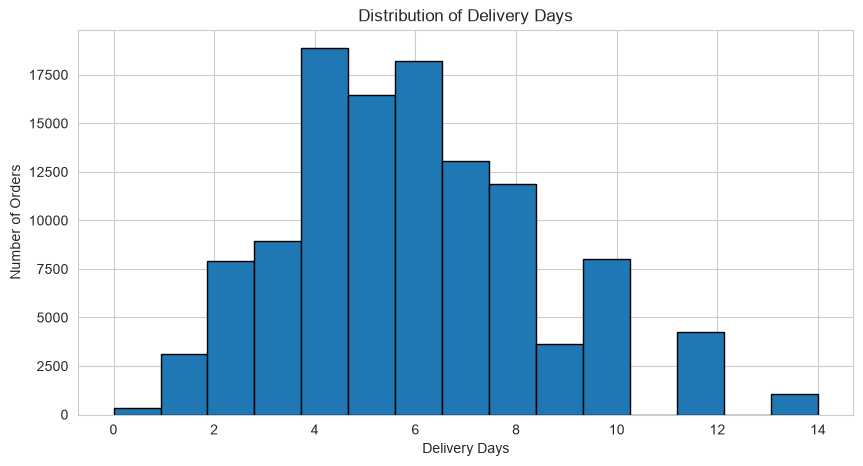

In [36]:
# Plot the distribution of delivery days

plt.figure(figsize=(10, 5))

plt.hist(df["Delivery_Days"].dropna(), bins=15, edgecolor="black")

plt.title("Distribution of Delivery Days")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Orders")

plt.show()

In [37]:
# Count orders by status
order_status_counts = df["Order_Status"].value_counts()

# Display the results
order_status_counts

Order_Status
Delivered Late       83394
Delivered On Time    32318
Processing            1950
Shipped               1646
Cancelled              591
Unknown                 59
In Transit              39
Pending                  3
Name: count, dtype: int64

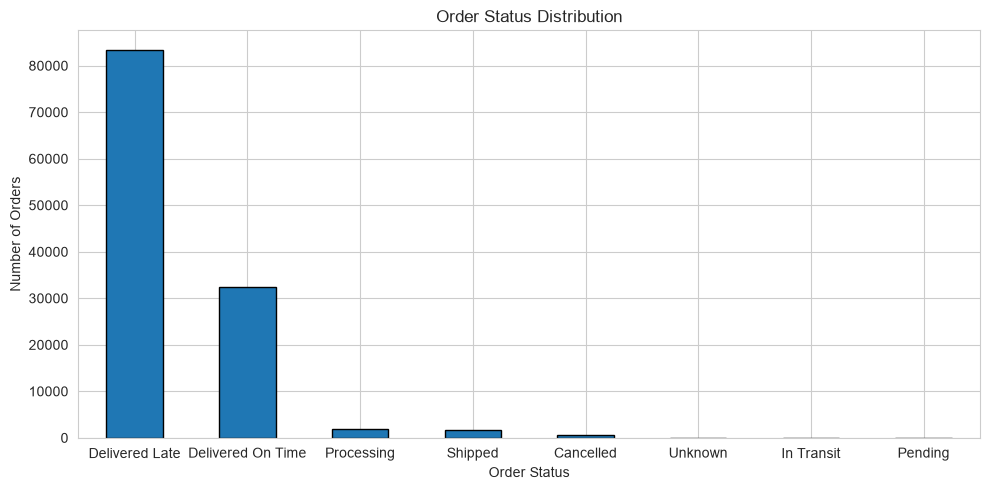

In [39]:
# Plot order status distribution
plt.figure(figsize=(10, 5))

order_status_counts.plot(
    kind="bar",
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

# Rotate x-axis labels for readability
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [40]:
# Count order lines by region
region_counts = df["Region"].value_counts()

# Display the results
region_counts

Region
South    47866
West     35853
North    24213
East     12068
Name: count, dtype: int64

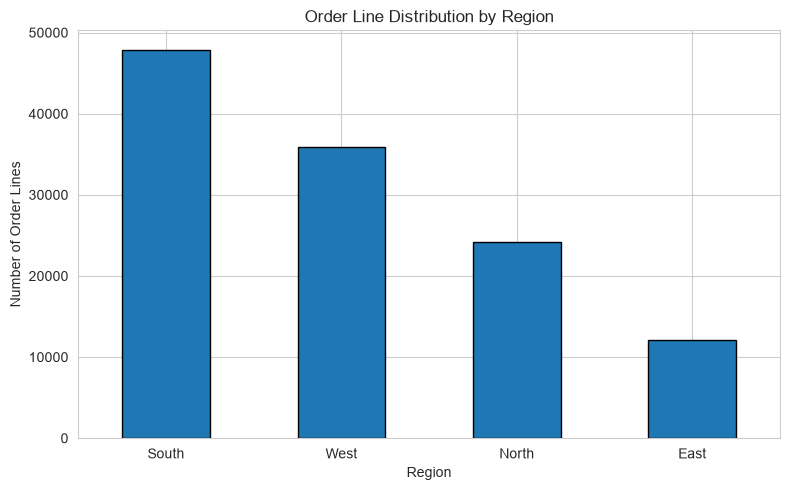

In [42]:
# Plot order lines by region
plt.figure(figsize=(8, 5))

region_counts.plot(
    kind="bar",
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Order Line Distribution by Region")
plt.xlabel("Region")
plt.ylabel("Number of Order Lines")

# Rotate x-axis labels for readability
plt.xticks(rotation=0)

# Display the chart
plt.tight_layout()
plt.show()

In [43]:
# Count order lines by product category
category_counts = df["Product_Category"].value_counts()

# Display the results
category_counts

Product_Category
Apparel            20259
Electronics        20157
Office Supplies    20042
Automotive         19903
Home & Kitchen     19842
Grocery            19797
Name: count, dtype: int64

In [44]:
# Check total dataset records
print("Total dataset records:", len(df))

# Check total category counts
print("Total category counts:", category_counts.sum())

# Check missing product categories
print("Missing product categories:",
      df["Product_Category"].isnull().sum())

# Display category counts again
print(category_counts)

Total dataset records: 120000
Total category counts: 120000
Missing product categories: 0
Product_Category
Apparel            20259
Electronics        20157
Office Supplies    20042
Automotive         19903
Home & Kitchen     19842
Grocery            19797
Name: count, dtype: int64


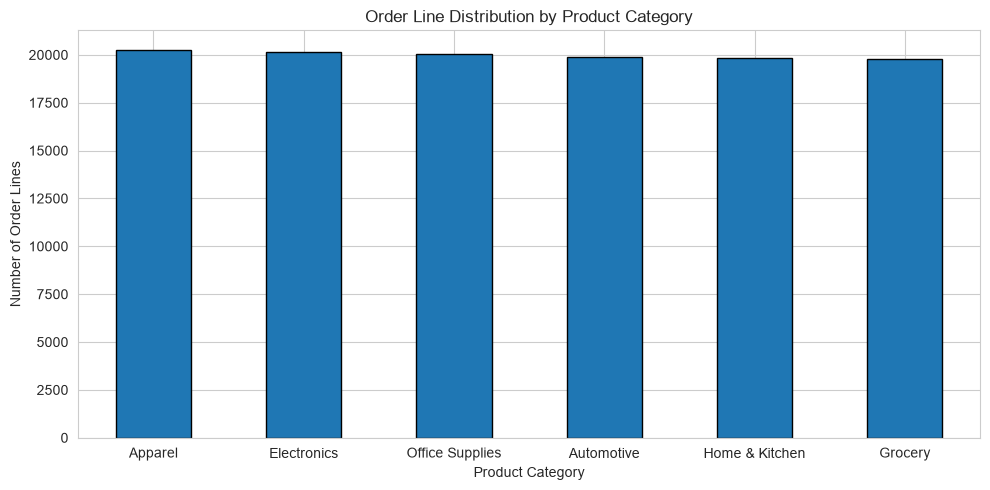

In [46]:
# Plot order lines by product category
plt.figure(figsize=(10, 5))

category_counts.plot(
    kind="bar",
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Order Line Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Order Lines")

# Rotate category labels
plt.xticks(rotation=0)

# Adjust chart spacing
plt.tight_layout()

# Display the chart
plt.show()

In [47]:
# Count order lines by shipping type
shipping_counts = df["Shipping_Type"].value_counts()

# Display the results
shipping_counts

Shipping_Type
Standard    57640
Economy     26420
Express     26385
Same Day     9555
Name: count, dtype: int64

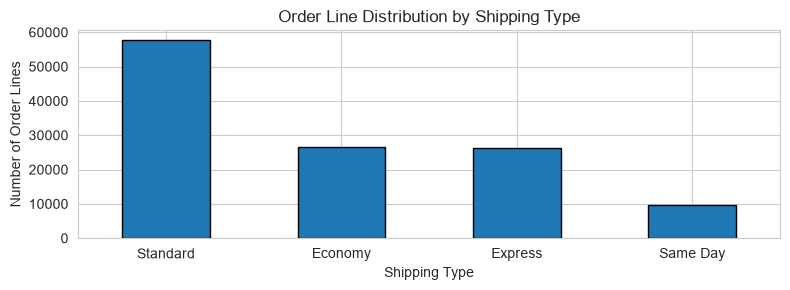

In [49]:
# Plot order lines by shipping type
plt.figure(figsize=(8, 3))

shipping_counts.plot(
    kind="bar",
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Order Line Distribution by Shipping Type")
plt.xlabel("Shipping Type")
plt.ylabel("Number of Order Lines")

# Rotate category labels
plt.xticks(rotation=0)

# Adjust chart spacing
plt.tight_layout()

# Display the chart
plt.show()

In [52]:
# Count order lines by payment method
payment_counts = df["Payment_Method"].value_counts()

# Display the results
payment_counts

# Count missing payment method values
print("Missing Payment Methods:",
      df["Payment_Method"].isnull().sum())

# Calculate total records including missing values
print("Total records:",
      payment_counts.sum() + df["Payment_Method"].isnull().sum())
# Display payment method counts
print(payment_counts)

Missing Payment Methods: 296
Total records: 120000
Payment_Method
UPI                 37978
Credit Card         30097
Debit Card          21537
Net Banking         18140
Cash On Delivery    11952
Name: count, dtype: int64


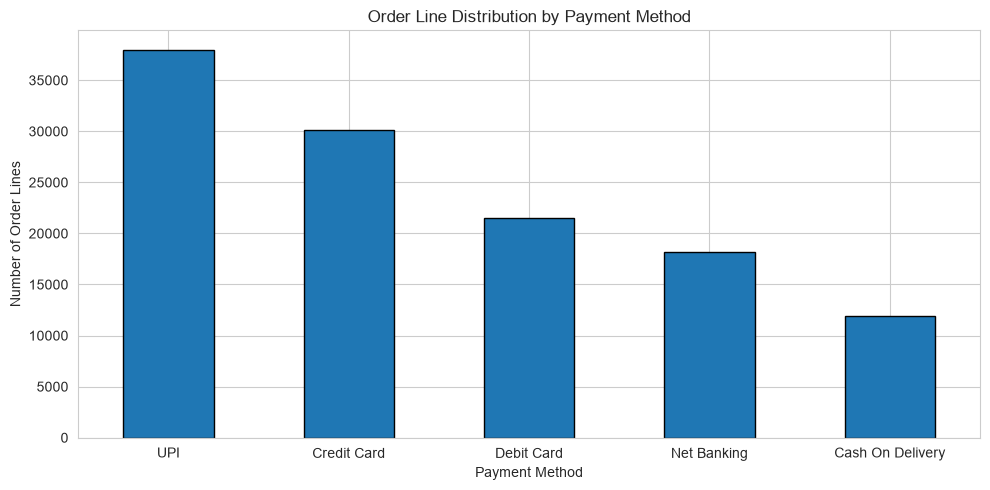

In [54]:
# Plot payment method distribution
plt.figure(figsize=(10, 5))

payment_counts.plot(
    kind="bar",
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Order Line Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Order Lines")

# Rotate category labels
plt.xticks(rotation=0)

# Adjust chart spacing
plt.tight_layout()

# Display the chart
plt.show()

In [55]:
# Count returned and non-returned order lines
return_counts = df["Return_Flag"].value_counts()

# Display the results
return_counts

Return_Flag
No     112959
Yes      7041
Name: count, dtype: int64

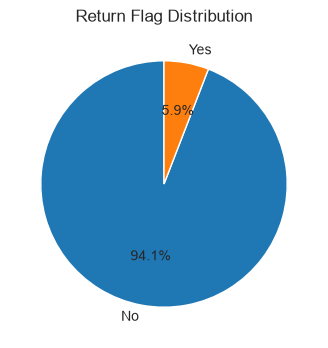

In [60]:
# Plot return flag distribution
plt.figure(figsize=(4, 4))

plt.pie(
    return_counts,
    labels=return_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

# Add chart title
plt.title("Return Flag Distribution")

# Display the chart
plt.show()

In [61]:
# Count order lines by inventory status
inventory_counts = df["Inventory_Status"].value_counts()

# Display the results
inventory_counts

Inventory_Status
Adequate Stock    98623
Low Stock         20330
Name: count, dtype: int64

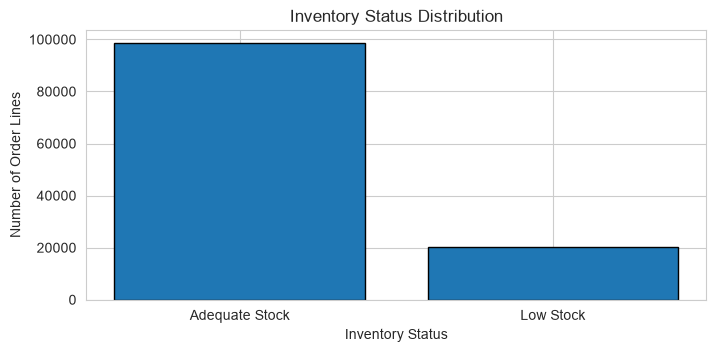

In [64]:
# Create figure
plt.figure(figsize=(8, 3.5))

# Create bar chart
plt.bar(
    inventory_counts.index,
    inventory_counts.values,
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Inventory Status Distribution")
plt.xlabel("Inventory Status")
plt.ylabel("Number of Order Lines")

# Display the chart
plt.show()

In [65]:
# Compare inventory status across product categories
category_inventory = pd.crosstab(
    df["Product_Category"],
    df["Inventory_Status"]
)

# Display the results
category_inventory

Inventory_Status,Adequate Stock,Low Stock
Product_Category,,
Apparel,16644,3434
Automotive,16333,3396
Electronics,16547,3452
Grocery,16351,3277
Home & Kitchen,16284,3370
Office Supplies,16464,3401


In [66]:
# Calculate total records in each category
category_totals = category_inventory.sum(axis=1)

# Calculate Low Stock percentage
low_stock_percentage = (
    category_inventory["Low Stock"] / category_totals
) * 100

# Sort categories by Low Stock percentage
low_stock_percentage.sort_values(ascending=False)

Product_Category
Electronics        17.260863
Automotive         17.213239
Home & Kitchen     17.146637
Office Supplies    17.120564
Apparel            17.103297
Grocery            16.695537
dtype: float64

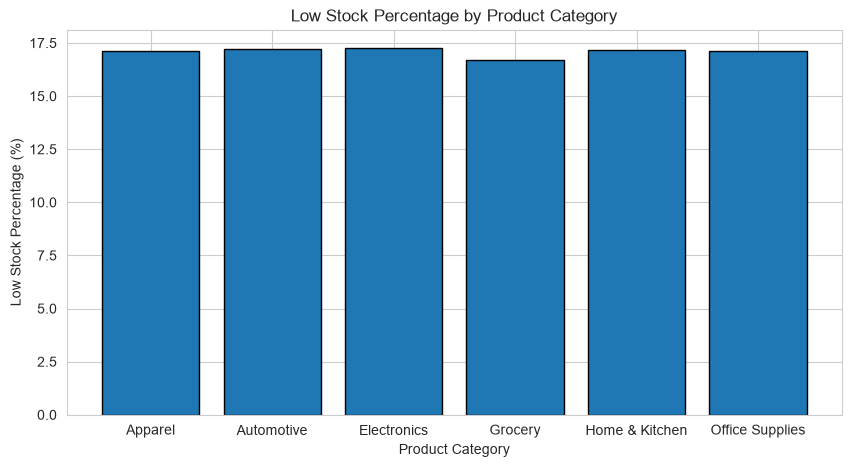

In [67]:
# Create figure
plt.figure(figsize=(10, 5))

# Create bar chart
plt.bar(
    low_stock_percentage.index,
    low_stock_percentage.values,
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Low Stock Percentage by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Low Stock Percentage (%)")

# Display the chart
plt.xticks(rotation=0)

plt.show()

In [68]:
# Compare inventory status across warehouses
warehouse_inventory = pd.crosstab(
    df["Warehouse_ID"],
    df["Inventory_Status"]
)

# Display the results
warehouse_inventory

Inventory_Status,Adequate Stock,Low Stock
Warehouse_ID,,
1,4011,766
2,3877,824
3,4044,790
4,3933,786
5,3936,831
6,3947,814
7,3875,848
8,4069,797
9,3953,807


In [69]:
# Calculate total records for each warehouse
warehouse_totals = warehouse_inventory.sum(axis=1)

# Calculate Low Stock percentage
warehouse_low_stock_percentage = (
    warehouse_inventory["Low Stock"] / warehouse_totals
) * 100

# Sort warehouses by Low Stock percentage
warehouse_low_stock_percentage.sort_values(
    ascending=False
)

Warehouse_ID
14    18.427621
7     17.954690
25    17.923280
18    17.833052
21    17.585412
2     17.528185
17    17.458307
20    17.450521
15    17.449664
5     17.432347
11    17.422532
16    17.271589
24    17.188152
12    17.120623
6     17.097248
9     16.953782
10    16.763848
4     16.656071
19    16.530484
8     16.378956
23    16.357432
3     16.342573
13    16.094332
22    16.093392
1     16.035169
dtype: float64

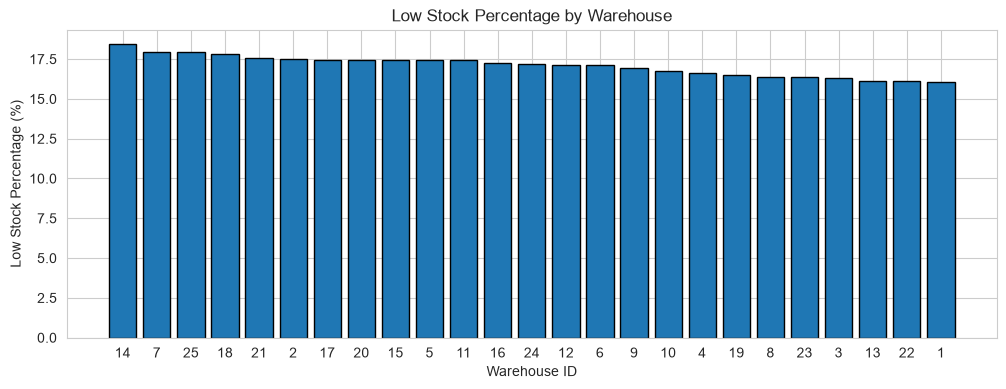

In [71]:
# Create figure
plt.figure(figsize=(12, 4))

# Sort percentages in descending order
warehouse_plot = warehouse_low_stock_percentage.sort_values(
    ascending=False
)

# Create bar chart
plt.bar(
    warehouse_plot.index.astype(str),
    warehouse_plot.values,
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Low Stock Percentage by Warehouse")
plt.xlabel("Warehouse ID")
plt.ylabel("Low Stock Percentage (%)")

# Display the chart
plt.show()

In [72]:
# Group delivery records by shipping type
shipping_performance = df.groupby("Shipping_Type").agg(
    Total_Valid_Deliveries=("On_Time_Flag", "count"),
    On_Time_Deliveries=("On_Time_Flag", "sum"),
    On_Time_Rate=("On_Time_Flag", "mean")
)

# Convert On-Time Rate into percentage
shipping_performance["On_Time_Rate"] = (
    shipping_performance["On_Time_Rate"] * 100
)

# Sort by On-Time Rate
shipping_performance.sort_values(
    by="On_Time_Rate",
    ascending=False
)

,Total_Valid_Deliveries,On_Time_Deliveries,On_Time_Rate
Shipping_Type,,,
Economy,25469,7203.0,28.281440
Express,25448,7129.0,28.013989
Standard,55663,15532.0,27.903634
Same Day,9216,2476.0,26.866319


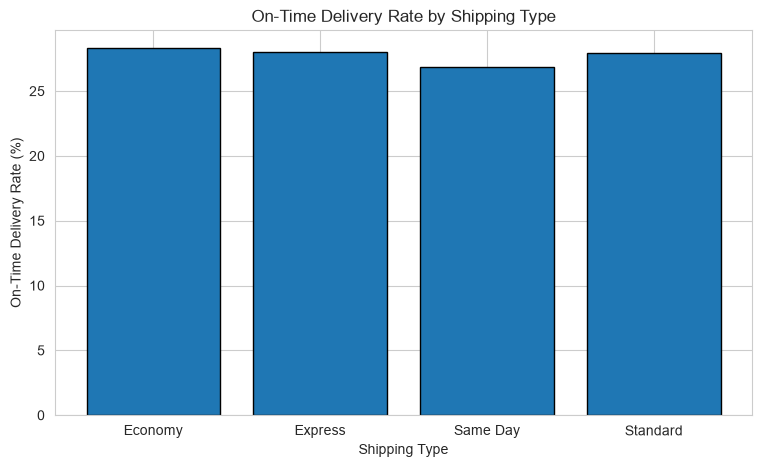

In [73]:
# Create figure
plt.figure(figsize=(9, 5))

# Create bar chart
plt.bar(
    shipping_performance.index,
    shipping_performance["On_Time_Rate"],
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("On-Time Delivery Rate by Shipping Type")
plt.xlabel("Shipping Type")
plt.ylabel("On-Time Delivery Rate (%)")

# Display the chart
plt.show()

In [74]:
# Calculate average delivery days for each shipping type
avg_delivery = df.groupby("Shipping_Type")["Delivery_Days"].mean()

# Sort from lowest to highest delivery time
avg_delivery.sort_values(ascending=True)

Shipping_Type
Same Day    3.154222
Express     4.093847
Standard    6.096104
Economy     8.085500
Name: Delivery_Days, dtype: float64

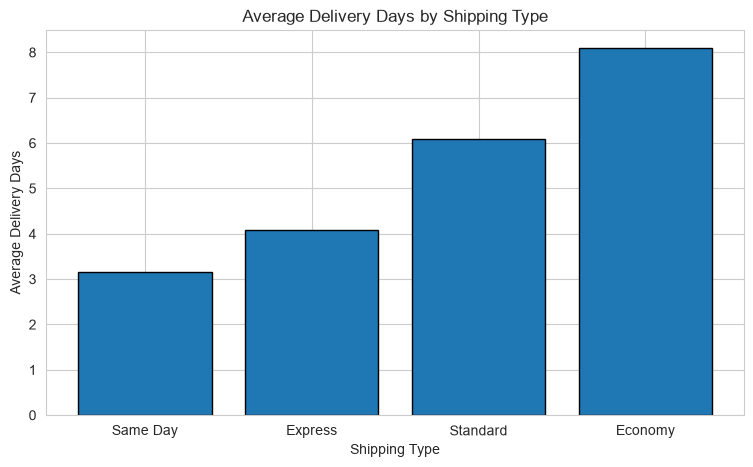

In [75]:
# Create figure
plt.figure(figsize=(9, 5))

# Create bar chart
plt.bar(
    avg_delivery.sort_values().index,
    avg_delivery.sort_values().values,
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Average Delivery Days by Shipping Type")
plt.xlabel("Shipping Type")
plt.ylabel("Average Delivery Days")

# Display the chart
plt.show()

In [76]:
# Group financial metrics by product category
category_financials = df.groupby("Product_Category").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit_Margin=("Profit_Margin", "mean")
)

# Convert Profit Margin into percentage
category_financials["Average_Profit_Margin"] *= 100

# Display results sorted by Revenue
category_financials.sort_values(
    by="Total_Revenue",
    ascending=False
)

,Total_Revenue,Total_Profit,Average_Profit_Margin
Product_Category,,,
Electronics,37054192.67,9155075.99,23.905733
Automotive,36801678.09,9099299.60,23.958069
Office Supplies,36780238.84,9063352.36,23.915497
Apparel,36496976.03,9086075.61,24.058804
Grocery,36331473.96,8994583.70,23.996379
Home & Kitchen,35817052.33,8893418.57,23.903192


In [77]:
# Calculate Overall Profit Margin
category_financials["Overall_Profit_Margin"] = (
    category_financials["Total_Profit"] /
    category_financials["Total_Revenue"]
) * 100

# Display financial results
category_financials.sort_values(
    by="Total_Revenue",
    ascending=False
)

,Total_Revenue,Total_Profit,Average_Profit_Margin,Overall_Profit_Margin
Product_Category,,,,
Electronics,37054192.67,9155075.99,23.905733,24.707261
Automotive,36801678.09,9099299.60,23.958069,24.725230
Office Supplies,36780238.84,9063352.36,23.915497,24.641907
Apparel,36496976.03,9086075.61,24.058804,24.895420
Grocery,36331473.96,8994583.70,23.996379,24.757002
Home & Kitchen,35817052.33,8893418.57,23.903192,24.830124


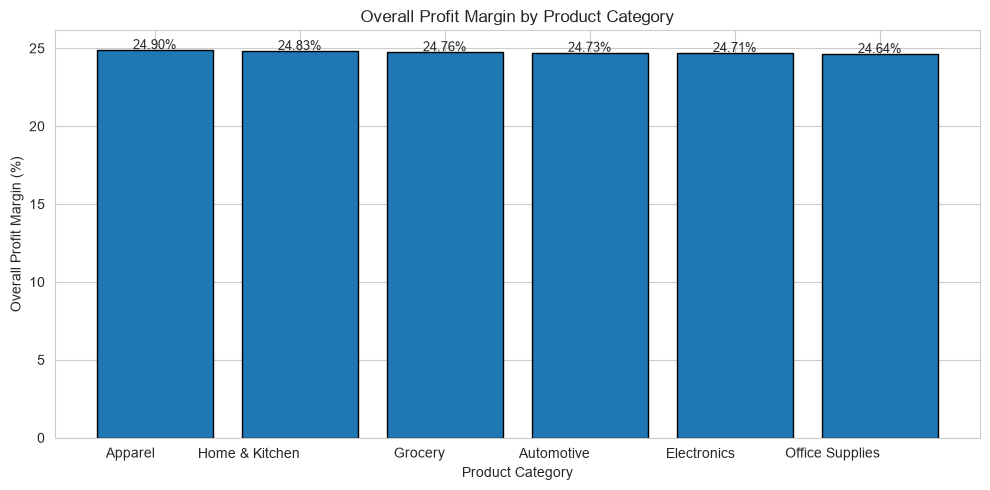

In [80]:
# Sort categories by Overall Profit Margin
margin_data = category_financials.sort_values(
    by="Overall_Profit_Margin",
    ascending=False
)

# Set chart size
plt.figure(figsize=(10, 5))

# Create bar chart
plt.bar(
    margin_data.index,
    margin_data["Overall_Profit_Margin"],
    edgecolor="black"
)

# Add chart title and axis labels
plt.title("Overall Profit Margin by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Overall Profit Margin (%)")

# Add percentage labels above each bar
for index, value in enumerate(margin_data["Overall_Profit_Margin"]):
    plt.text(index, value + 0.05, f"{value:.2f}%",
             ha="center", fontsize=9)

# Rotate category names for readability
plt.xticks(rotation=0, ha="right")

# Display chart
plt.tight_layout()
plt.show()

In [81]:
# Calculate monthly revenue and order-line counts
monthly_analysis = (
    df.groupby(df["Order_Date"].dt.to_period("M"))
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Order_Lines=("Order_Line_ID", "count")
    )
    .reset_index()
)

# Rename the date column
monthly_analysis = monthly_analysis.rename(
    columns={"Order_Date": "Month"}
)

# Convert month into readable text
monthly_analysis["Month"] = monthly_analysis["Month"].astype(str)

# Display monthly analysis
monthly_analysis

,Month,Total_Revenue,Total_Order_Lines
0,2024-01,9065317.85,5156
1,2024-02,8734377.27,4764
2,2024-03,9509952.96,5176
3,2024-04,9192160.39,4854
4,2024-05,9250570.75,5121
5,2024-06,9046142.63,4906
6,2024-07,9249097.27,5042
7,2024-08,9511106.97,5202
8,2024-09,8722666.92,4922
9,2024-10,8937076.12,5039


In [82]:
# Identify the month with the highest revenue
highest_revenue_month = monthly_analysis.loc[
    monthly_analysis["Total_Revenue"].idxmax()
]

# Identify the month with the lowest revenue
lowest_revenue_month = monthly_analysis.loc[
    monthly_analysis["Total_Revenue"].idxmin()
]

# Display the results
print("Highest Revenue Month:")
print(highest_revenue_month)

print("\nLowest Revenue Month:")
print(lowest_revenue_month)

Highest Revenue Month:
Month                   2025-03
Total_Revenue        9528473.54
Total_Order_Lines          5087
Name: 14, dtype: object

Lowest Revenue Month:
Month                   2025-02
Total_Revenue        8278991.76
Total_Order_Lines          4568
Name: 13, dtype: object


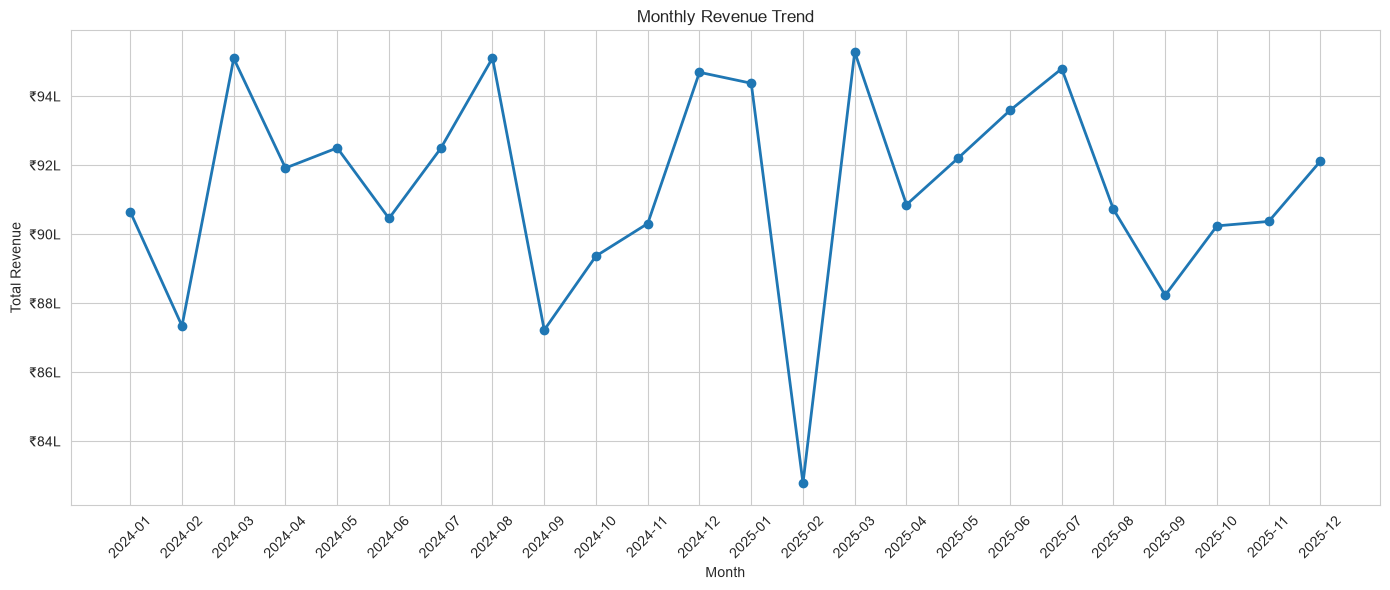

In [84]:
# Set chart size
plt.figure(figsize=(14, 6))

# Create monthly revenue line chart
plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Total_Revenue"],
    marker="o",
    linewidth=2
)

# Add chart title and axis labels
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

# Format Y-axis values in lakhs
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"₹{x/100000:.0f}L")
)

# Rotate month labels
plt.xticks(rotation=45)

# Add grid lines
plt.grid(True)

# Adjust chart spacing
plt.tight_layout()

# Display chart
plt.show()

In [85]:
# Calculate monthly financial performance
monthly_profit = (
    df.groupby(df["Order_Date"].dt.to_period("M"))
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Profit=("Profit", "sum")
    )
)

# Calculate overall monthly profit margin
monthly_profit["Profit_Margin"] = (
    monthly_profit["Total_Profit"] /
    monthly_profit["Total_Revenue"]
) * 100

# Display monthly financial analysis
monthly_profit

,Total_Revenue,Total_Profit,Profit_Margin
Order_Date,,,
2024-01,9065317.85,2265101.06,24.986449
2024-02,8734377.27,2170947.32,24.855204
2024-03,9509952.96,2339669.58,24.602325
2024-04,9192160.39,2258948.44,24.574728
2024-05,9250570.75,2309180.22,24.962570
2024-06,9046142.63,2250980.72,24.883321
2024-07,9249097.27,2295955.09,24.823559
2024-08,9511106.97,2366806.47,24.884658
2024-09,8722666.92,2146290.26,24.605895


In [86]:
# Identify the month with the highest profit
highest_profit_month = monthly_profit.loc[
    monthly_profit["Total_Profit"].idxmax()
]

# Identify the month with the lowest profit
lowest_profit_month = monthly_profit.loc[
    monthly_profit["Total_Profit"].idxmin()
]

# Identify the month with the highest profit margin
highest_margin_month = monthly_profit.loc[
    monthly_profit["Profit_Margin"].idxmax()
]

# Identify the month with the lowest profit margin
lowest_margin_month = monthly_profit.loc[
    monthly_profit["Profit_Margin"].idxmin()
]

# Display results
print("Highest Profit Month:")
print(highest_profit_month)

print("\nLowest Profit Month:")
print(lowest_profit_month)

print("\nHighest Profit Margin Month:")
print(highest_margin_month)

print("\nLowest Profit Margin Month:")
print(lowest_margin_month)

Highest Profit Month:
Total_Revenue    9.528474e+06
Total_Profit     2.391156e+06
Profit_Margin    2.509485e+01
Name: 2025-03, dtype: float64

Lowest Profit Month:
Total_Revenue    8.278992e+06
Total_Profit     2.019846e+06
Profit_Margin    2.439725e+01
Name: 2025-02, dtype: float64

Highest Profit Margin Month:
Total_Revenue    9.437937e+06
Total_Profit     2.376724e+06
Profit_Margin    2.518266e+01
Name: 2025-01, dtype: float64

Lowest Profit Margin Month:
Total_Revenue    9.037355e+06
Total_Profit     2.151307e+06
Profit_Margin    2.380461e+01
Name: 2025-11, dtype: float64


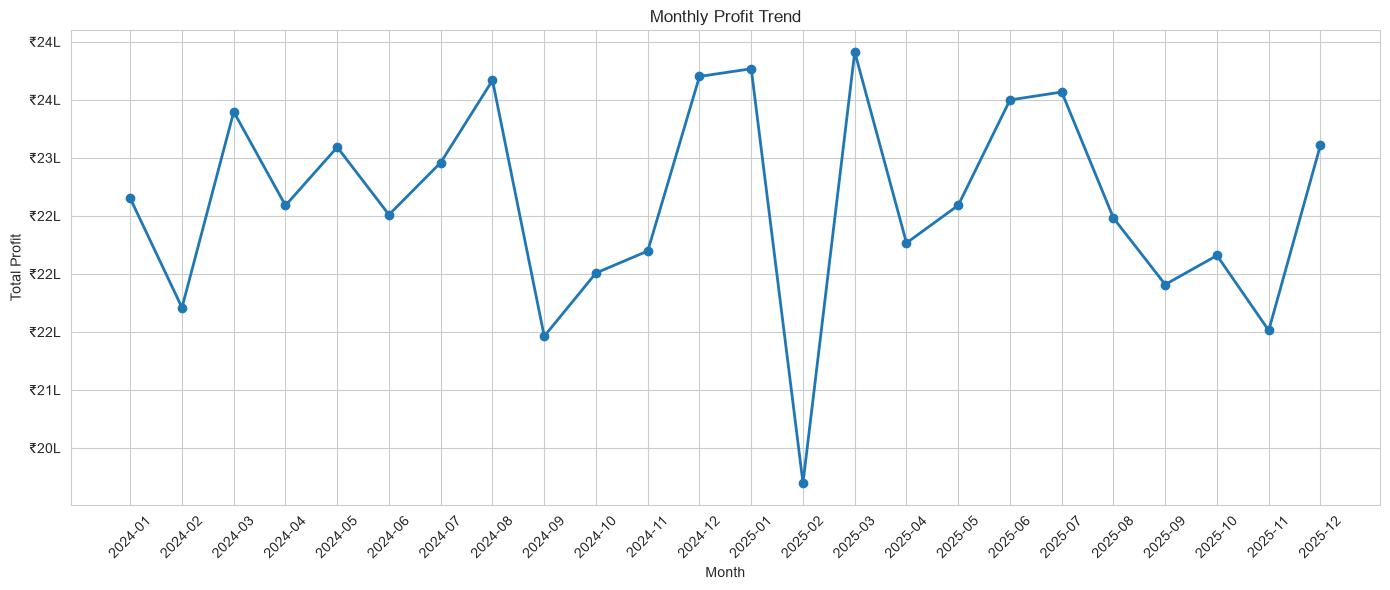

In [87]:
# Set chart size
plt.figure(figsize=(14, 6))

# Create monthly profit line chart
plt.plot(
    monthly_profit.index.astype(str),
    monthly_profit["Total_Profit"],
    marker="o",
    linewidth=2
)

# Add chart title and axis labels
plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit")

# Format Y-axis values in lakhs
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"₹{x/100000:.0f}L")
)

# Rotate month labels
plt.xticks(rotation=45)

# Add grid lines
plt.grid(True)

# Adjust chart spacing
plt.tight_layout()

# Display chart
plt.show()

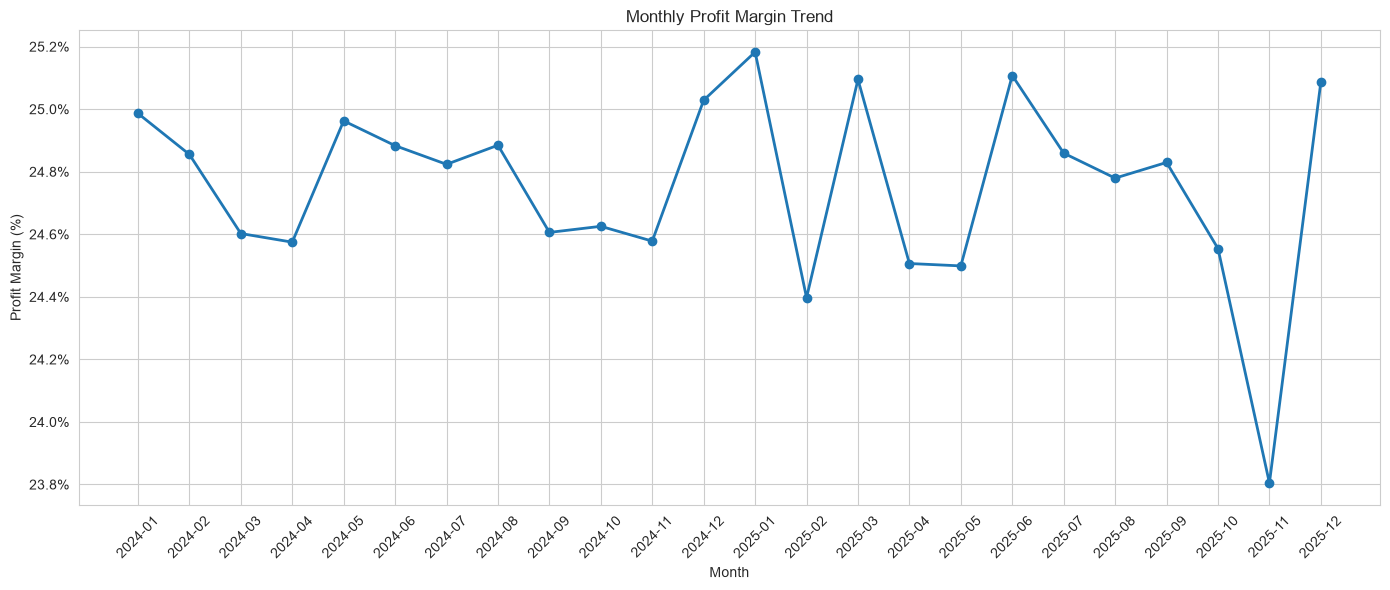

In [88]:
# Set chart size
plt.figure(figsize=(14, 6))

# Create monthly profit margin line chart
plt.plot(
    monthly_profit.index.astype(str),
    monthly_profit["Profit_Margin"],
    marker="o",
    linewidth=2
)

# Add chart title and axis labels
plt.title("Monthly Profit Margin Trend")
plt.xlabel("Month")
plt.ylabel("Profit Margin (%)")

# Format Y-axis with percentage symbol
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{x:.1f}%")
)

# Rotate month labels
plt.xticks(rotation=45)

# Add grid lines
plt.grid(True)

# Adjust chart spacing
plt.tight_layout()

# Display chart
plt.show()

In [89]:
# Calculate total revenue and profit for each customer
customer_analysis = (
    df.groupby("Customer_ID")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Order_Lines=("Order_Line_ID", "count")
    )
)

# Identify top 10 customers by revenue
top_10_customers = customer_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
).head(10)

# Display results
top_10_customers

,Total_Revenue,Total_Profit,Total_Order_Lines
Customer_ID,,,
9486,66424.32,23648.07,7
6039,63996.75,20147.29,7
15763,56136.72,22717.11,14
6360,55669.49,17728.16,13
12485,55115.07,6958.35,11
4915,54982.86,12034.57,11
9532,53861.92,11150.53,15
8621,53532.52,-1364.70,11
4133,52957.66,5792.78,12


In [90]:
# Sort customers by total profit
top_10_profit_customers = customer_analysis.sort_values(
    by="Total_Profit",
    ascending=False
).head(10)

# Display top 10 profitable customers
top_10_profit_customers

,Total_Revenue,Total_Profit,Total_Order_Lines
Customer_ID,,,
9486,66424.32,23648.07,7
15763,56136.72,22717.11,14
13384,50090.68,21433.10,10
6039,63996.75,20147.29,7
13227,39965.02,18490.92,7
6360,55669.49,17728.16,13
14984,30818.79,17306.05,7
3339,51922.14,16934.93,18
2268,47675.47,16826.78,11


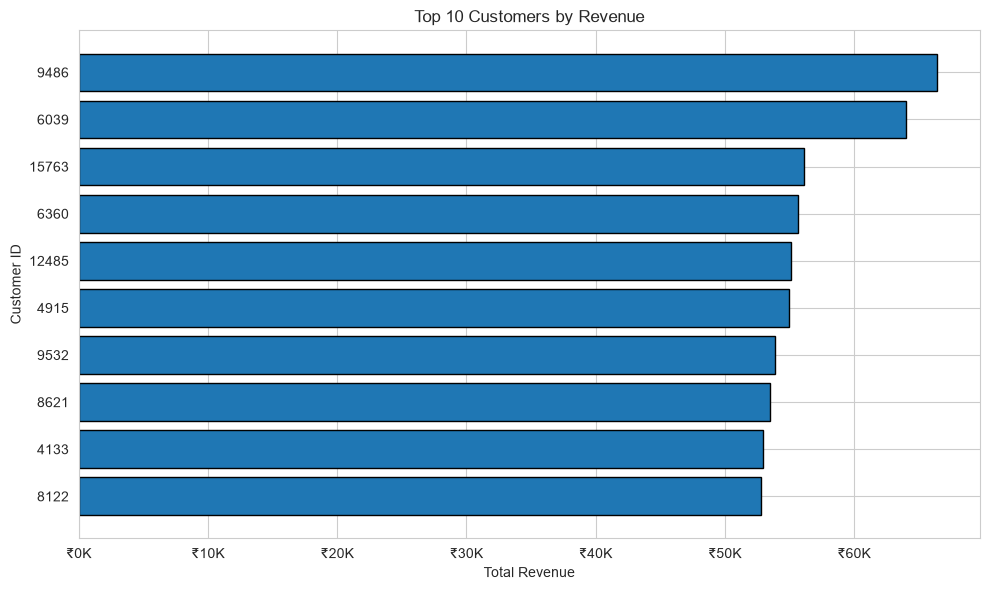

In [91]:
# Sort top 10 customers by revenue
revenue_chart = top_10_customers.sort_values(
    by="Total_Revenue",
    ascending=True
)

# Set chart size
plt.figure(figsize=(10, 6))

# Create horizontal bar chart
plt.barh(
    revenue_chart.index.astype(str),
    revenue_chart["Total_Revenue"],
    edgecolor="black"
)

# Add chart title and labels
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")

# Format revenue values in thousands
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"₹{x/1000:.0f}K")
)

# Adjust chart spacing
plt.tight_layout()

# Display chart
plt.show()

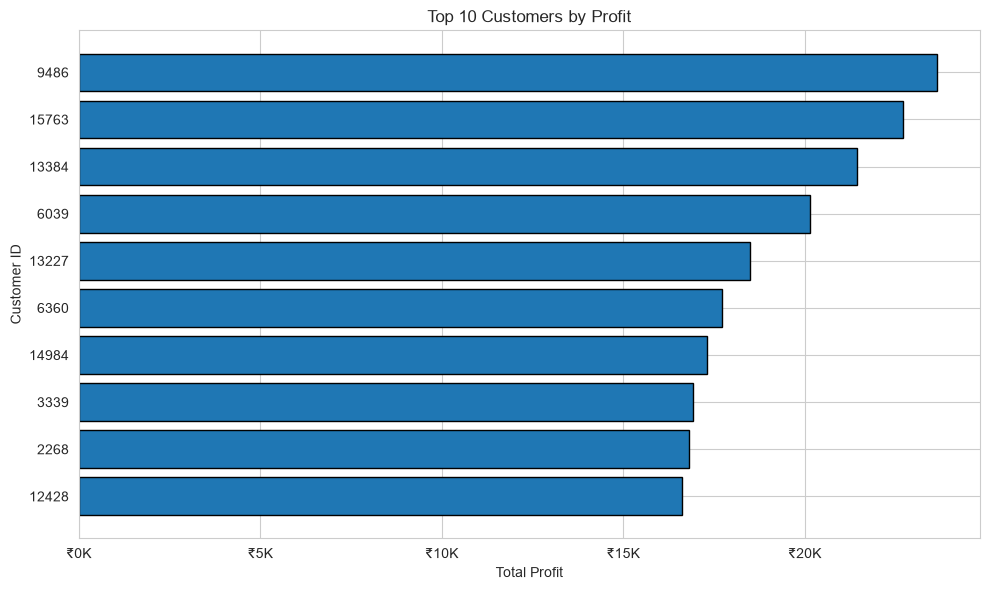

In [92]:
# Calculate total profit for each customer
customer_profit = df.groupby("Customer_ID").agg(
    Total_Profit=("Profit", "sum")
)

# Select top 10 customers by profit
top_10_profit = customer_profit.nlargest(
    10, "Total_Profit"
)

# Sort for horizontal chart
profit_chart = top_10_profit.sort_values(
    by="Total_Profit",
    ascending=True
)

# Set chart size
plt.figure(figsize=(10, 6))

# Create horizontal bar chart
plt.barh(
    profit_chart.index.astype(str),
    profit_chart["Total_Profit"],
    edgecolor="black"
)

# Add chart title and labels
plt.title("Top 10 Customers by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Customer ID")

# Format profit values in thousands
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"₹{x/1000:.0f}K")
)

# Adjust chart spacing
plt.tight_layout()

# Display chart
plt.show()

In [93]:
# Calculate revenue and profit for each product
product_financials = df.groupby("Product_ID").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Order_Lines=("Order_Line_ID", "count")
)

# Select top 10 products by revenue
top_10_products = product_financials.nlargest(
    10, "Total_Revenue"
)

# Display results
top_10_products

,Total_Revenue,Total_Profit,Total_Order_Lines
Product_ID,,,
607,386644.40,106588.98,177
744,385618.46,107114.62,167
219,380612.01,87608.83,178
758,377731.81,96533.14,185
619,371426.45,76778.24,159
154,369717.88,93663.03,162
37,367175.66,95881.46,155
679,363956.67,81156.43,186
55,362662.37,84448.06,184


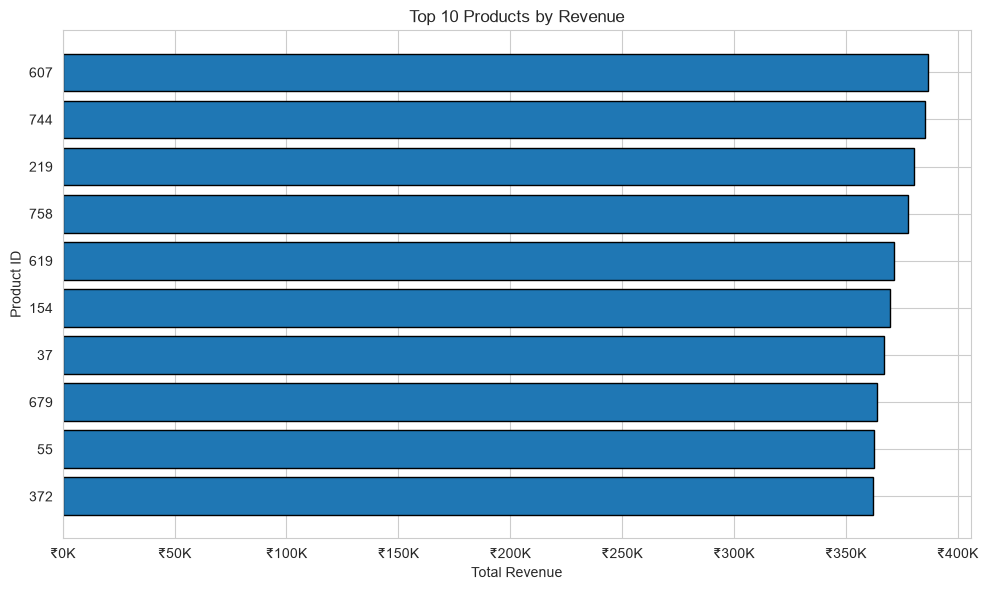

In [94]:
# Sort products by revenue for the chart
product_revenue_chart = top_10_products.sort_values(
    by="Total_Revenue",
    ascending=True
)

# Set chart size
plt.figure(figsize=(10, 6))

# Create horizontal bar chart
plt.barh(
    product_revenue_chart.index.astype(str),
    product_revenue_chart["Total_Revenue"],
    edgecolor="black"
)

# Add title and labels
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product ID")

# Format revenue in thousands
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"₹{x/1000:.0f}K")
)

plt.tight_layout()
plt.show()

In [95]:
# Select top 10 products by profit
top_10_products_profit = product_financials.nlargest(
    10, "Total_Profit"
)

# Display results
top_10_products_profit

,Total_Revenue,Total_Profit,Total_Order_Lines
Product_ID,,,
744,385618.46,107114.62,167
607,386644.40,106588.98,177
245,336006.54,103241.89,154
785,358792.98,97051.00,182
490,351072.85,96627.10,185
758,377731.81,96533.14,185
37,367175.66,95881.46,155
728,359914.76,95817.61,168
165,334420.68,95236.64,157


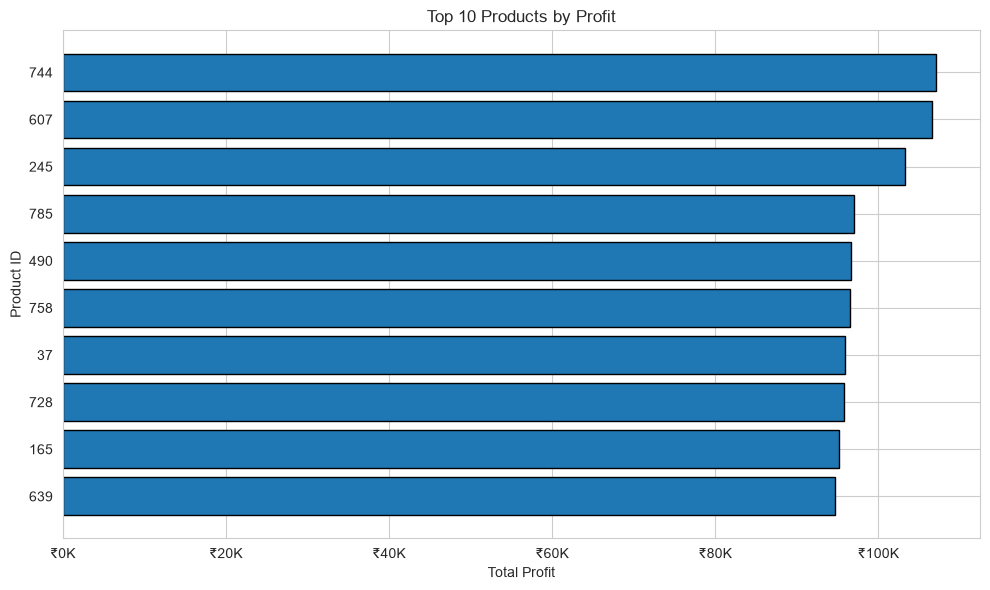

In [96]:
# Sort products by profit for the chart
product_profit_chart = top_10_products_profit.sort_values(
    by="Total_Profit",
    ascending=True
)

# Set chart size
plt.figure(figsize=(10, 6))

# Create horizontal bar chart
plt.barh(
    product_profit_chart.index.astype(str),
    product_profit_chart["Total_Profit"],
    edgecolor="black"
)

# Add title and labels
plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product ID")

# Format profit values in thousands
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"₹{x/1000:.0f}K")
)

# Adjust chart spacing
plt.tight_layout()

# Display chart
plt.show()

In [97]:
# Calculate profit margin for each product
product_financials["Profit_Margin"] = (
    product_financials["Total_Profit"] /
    product_financials["Total_Revenue"]
) * 100

# Select top 10 products by revenue
top_10_product_margin = product_financials.nlargest(
    10, "Total_Revenue"
)

# Sort products by profit margin
top_10_product_margin = top_10_product_margin.sort_values(
    by="Profit_Margin",
    ascending=False
)

# Display results
top_10_product_margin

,Total_Revenue,Total_Profit,Total_Order_Lines,Profit_Margin
Product_ID,,,,
744,385618.46,107114.62,167,27.777358
607,386644.40,106588.98,177,27.567703
37,367175.66,95881.46,155,26.113240
758,377731.81,96533.14,185,25.556000
154,369717.88,93663.03,162,25.333649
55,362662.37,84448.06,184,23.285587
219,380612.01,87608.83,178,23.017884
679,363956.67,81156.43,186,22.298377
619,371426.45,76778.24,159,20.671183


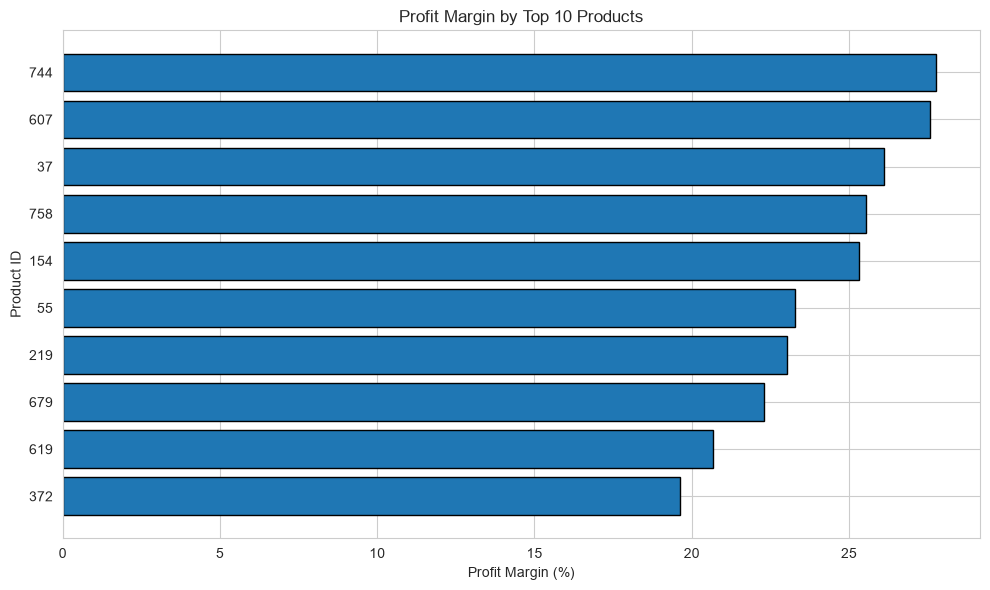

In [98]:
# Sort products by profit margin
margin_chart = top_10_product_margin.sort_values(
    by="Profit_Margin",
    ascending=True
)

# Set chart size
plt.figure(figsize=(10, 6))

# Create horizontal bar chart
plt.barh(
    margin_chart.index.astype(str),
    margin_chart["Profit_Margin"],
    edgecolor="black"
)

# Add title and labels
plt.title("Profit Margin by Top 10 Products")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product ID")

# Adjust chart spacing
plt.tight_layout()

# Display chart
plt.show()

In [99]:
# Calculate financial performance by product category
category_performance = df.groupby("Product_Category").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Order_Lines=("Order_Line_ID", "count")
)

# Calculate overall profit margin
category_performance["Profit_Margin"] = (
    category_performance["Total_Profit"] /
    category_performance["Total_Revenue"]
) * 100

# Sort categories by revenue
category_performance = category_performance.sort_values(
    by="Total_Revenue",
    ascending=False
)

# Display results
category_performance

,Total_Revenue,Total_Profit,Total_Order_Lines,Profit_Margin
Product_Category,,,,
Electronics,37054192.67,9155075.99,20157,24.707261
Automotive,36801678.09,9099299.60,19903,24.725230
Office Supplies,36780238.84,9063352.36,20042,24.641907
Apparel,36496976.03,9086075.61,20259,24.895420
Grocery,36331473.96,8994583.70,19797,24.757002
Home & Kitchen,35817052.33,8893418.57,19842,24.830124


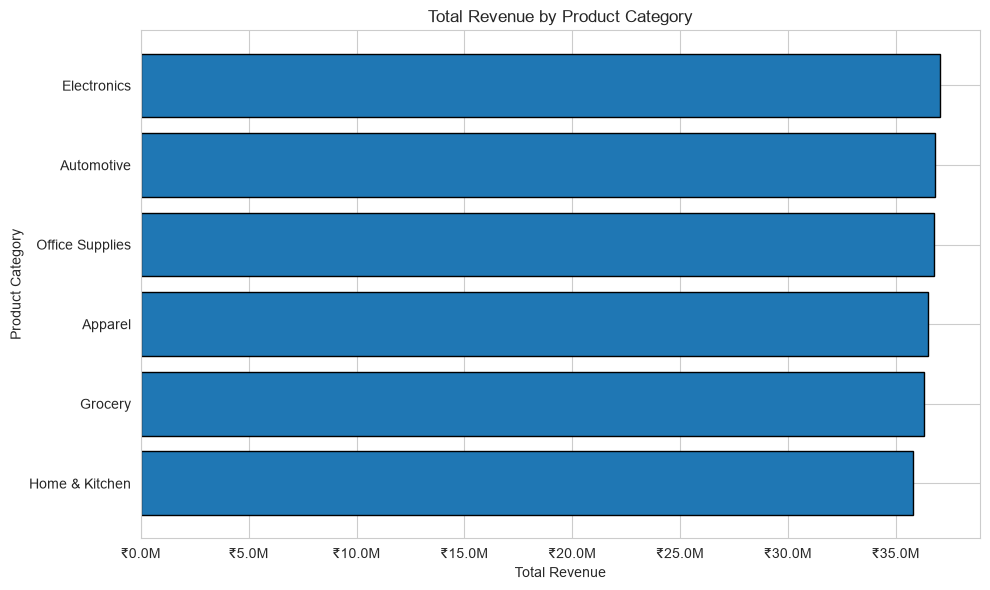

In [100]:
# Sort categories by revenue
category_revenue_chart = category_performance.sort_values(
    by="Total_Revenue",
    ascending=True
)

# Set chart size
plt.figure(figsize=(10, 6))

# Create horizontal bar chart
plt.barh(
    category_revenue_chart.index,
    category_revenue_chart["Total_Revenue"],
    edgecolor="black"
)

# Add title and labels
plt.title("Total Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")

# Format revenue in millions
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"₹{x/1000000:.1f}M")
)

plt.tight_layout()
plt.show()

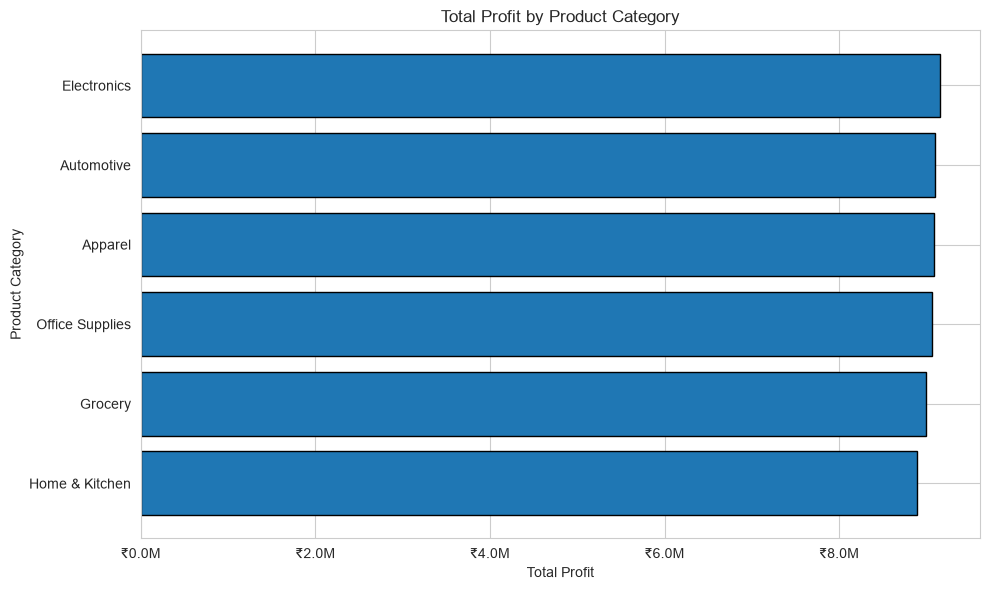

In [101]:
# Sort categories by profit
category_profit_chart = category_performance.sort_values(
    by="Total_Profit",
    ascending=True
)

# Set chart size
plt.figure(figsize=(10, 6))

# Create horizontal bar chart
plt.barh(
    category_profit_chart.index,
    category_profit_chart["Total_Profit"],
    edgecolor="black"
)

# Add title and labels
plt.title("Total Profit by Product Category")
plt.xlabel("Total Profit")
plt.ylabel("Product Category")

# Format profit in millions
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"₹{x/1000000:.1f}M")
)

plt.tight_layout()
plt.show()

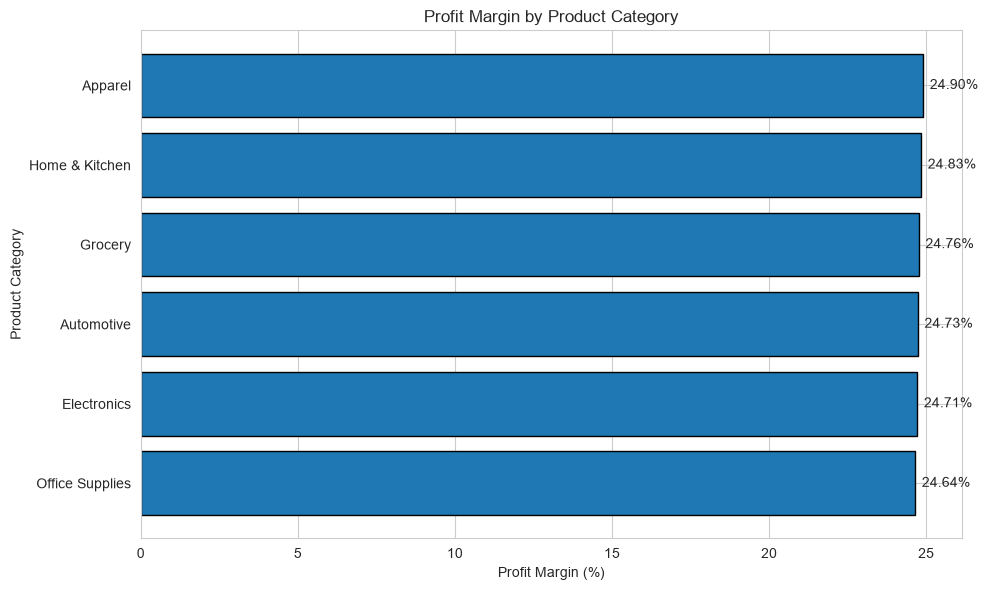

In [103]:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    category_margin_chart.index,
    category_margin_chart["Profit_Margin"],
    edgecolor="black"
)

plt.bar_label(bars, fmt="%.2f%%", padding=5)

plt.title("Profit Margin by Product Category")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [104]:
# Calculate financial performance by region
region_financials = df.groupby("Region").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Order_Lines=("Order_Line_ID", "count")
)

# Calculate overall profit margin
region_financials["Profit_Margin"] = (
    region_financials["Total_Profit"] /
    region_financials["Total_Revenue"]
) * 100

# Sort regions by total revenue
region_financials = region_financials.sort_values(
    by="Total_Revenue",
    ascending=False
)

# Display results
region_financials

,Total_Revenue,Total_Profit,Total_Order_Lines,Profit_Margin
Region,,,,
South,87413599.14,21656793.97,47866,24.775086
West,65503892.21,16280796.76,35853,24.854701
North,44570362.61,10989570.97,24213,24.656678
East,21793757.96,5364644.13,12068,24.615508


In [123]:
def plot_crore_chart(data, column, title, xlabel):

    # Convert rupees into crores
    values = data[column] / 10000000

    plt.figure(figsize=(9, 5))

    bars = plt.bar(
        data.index.astype(str),
        values,
        edgecolor="black"
    )

    # Add value labels above bars
    plt.bar_label(
        bars,
        labels=[f"₹{value:.2f} Cr" for value in values],
        padding=3
    )

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Amount (₹ Crores)")

    # Display Y-axis values in crores
    plt.ticklabel_format(
        axis="y",
        style="plain",
        useOffset=False
    )

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

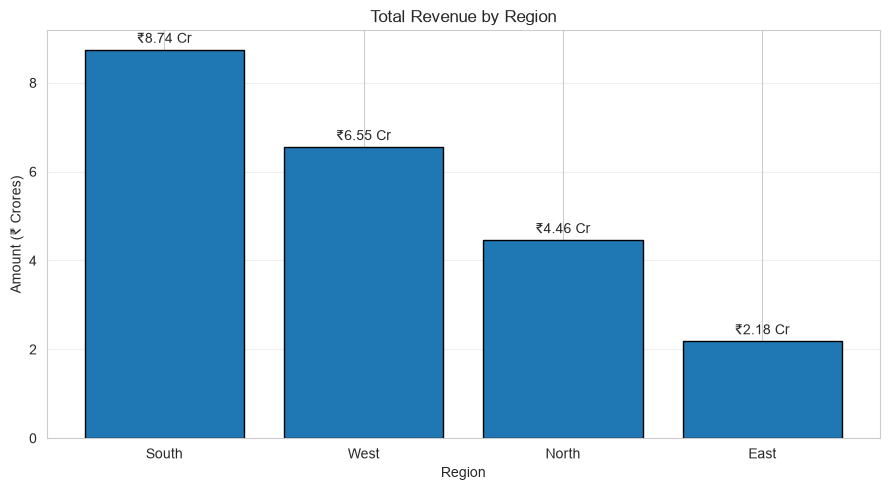

In [124]:
plot_crore_chart(
    region_financials,
    "Total_Revenue",
    "Total Revenue by Region",
    "Region"
)

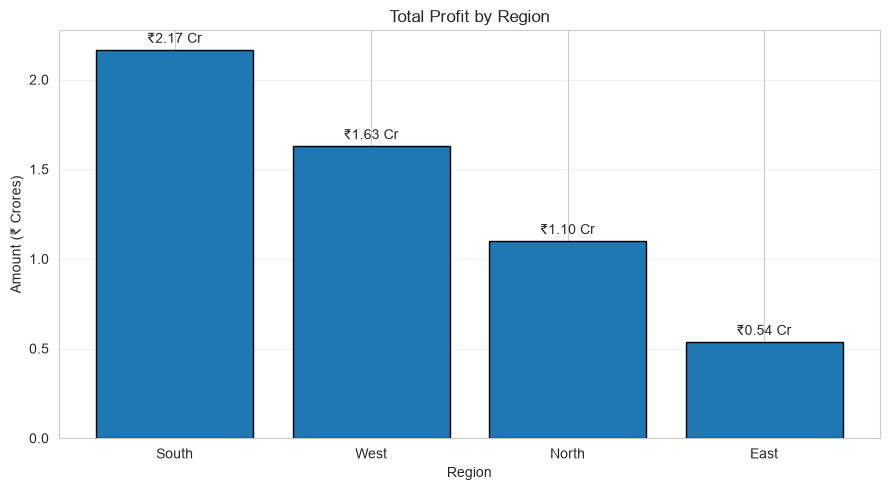

In [125]:
plot_crore_chart(
    region_financials,
    "Total_Profit",
    "Total Profit by Region",
    "Region"
)

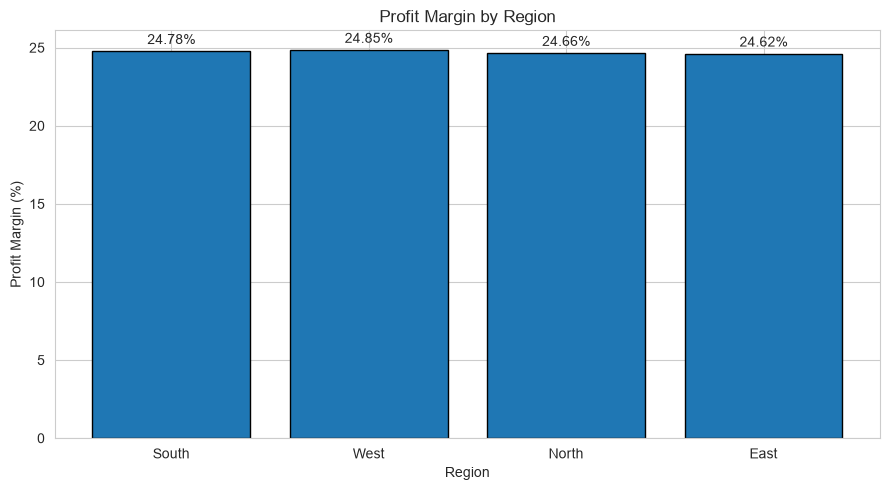

In [107]:
# Plot profit margin by region
plt.figure(figsize=(9, 5))

bars = plt.bar(
    region_financials.index,
    region_financials["Profit_Margin"],
    edgecolor="black"
)

plt.bar_label(
    bars,
    fmt="%.2f%%",
    padding=3
)

plt.title("Profit Margin by Region")
plt.xlabel("Region")
plt.ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

In [108]:
# Calculate financial performance by payment method
payment_financials = df.groupby("Payment_Method").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Order_Lines=("Order_Line_ID", "count")
)

# Calculate overall profit margin
payment_financials["Profit_Margin"] = (
    payment_financials["Total_Profit"] /
    payment_financials["Total_Revenue"]
) * 100

# Sort by revenue
payment_financials = payment_financials.sort_values(
    by="Total_Revenue",
    ascending=False
)

payment_financials

,Total_Revenue,Total_Profit,Total_Order_Lines,Profit_Margin
Payment_Method,,,,
UPI,69688135.24,17254369.38,37978,24.759407
Credit Card,54458628.74,13455362.38,30097,24.707494
Debit Card,39483630.69,9768427.51,21537,24.740449
Net Banking,33327175.06,8244907.30,18140,24.739292
Cash On Delivery,21738839.41,5427287.01,11952,24.965854


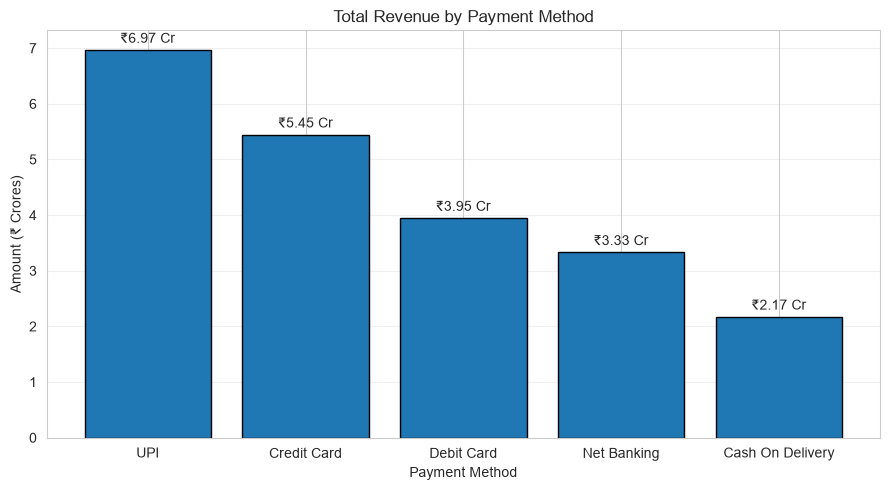

In [126]:
plot_crore_chart(
    payment_financials,
    "Total_Revenue",
    "Total Revenue by Payment Method",
    "Payment Method"
)

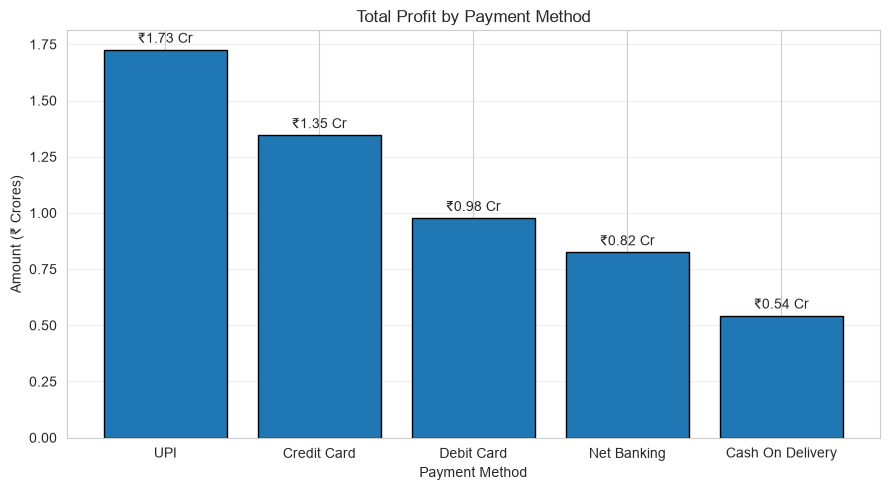

In [127]:
plot_crore_chart(
    payment_financials,
    "Total_Profit",
    "Total Profit by Payment Method",
    "Payment Method"
)

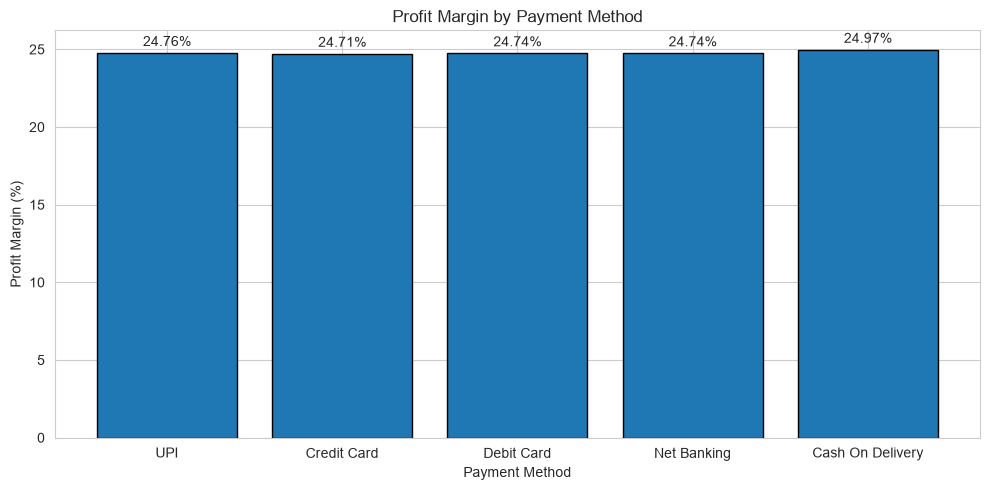

In [115]:
# Plot profit margin by payment method
plt.figure(figsize=(10, 5))

bars = plt.bar(
    payment_financials.index,
    payment_financials["Profit_Margin"],
    edgecolor="black"
)

plt.bar_label(
    bars,
    fmt="%.2f%%",
    padding=3
)

plt.title("Profit Margin by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [116]:
# Calculate financial performance by shipping type
shipping_financials = df.groupby("Shipping_Type").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Shipping_Cost=("Shipping_Cost", "sum"),
    Total_Order_Lines=("Order_Line_ID", "count")
)

# Calculate overall profit margin
shipping_financials["Profit_Margin"] = (
    shipping_financials["Total_Profit"] /
    shipping_financials["Total_Revenue"]
) * 100

# Calculate average shipping cost per order line
shipping_financials["Avg_Shipping_Cost"] = (
    shipping_financials["Total_Shipping_Cost"] /
    df.groupby("Shipping_Type")["Shipping_Cost"].count()
)

# Sort by revenue
shipping_financials = shipping_financials.sort_values(
    by="Total_Revenue",
    ascending=False
)

shipping_financials

,Total_Revenue,Total_Profit,Total_Shipping_Cost,Total_Order_Lines,Profit_Margin,Avg_Shipping_Cost
Shipping_Type,,,,,,
Standard,1.057074e+08,26009034.37,18143106.34,57640,24.604748,316.594942
Express,4.831985e+07,11975235.59,10379628.44,26385,24.783264,395.715915
Economy,4.829977e+07,12117764.59,8263631.32,26420,25.088659,314.565334
Same Day,1.695461e+07,4189771.28,4502118.89,9555,24.711687,473.707796


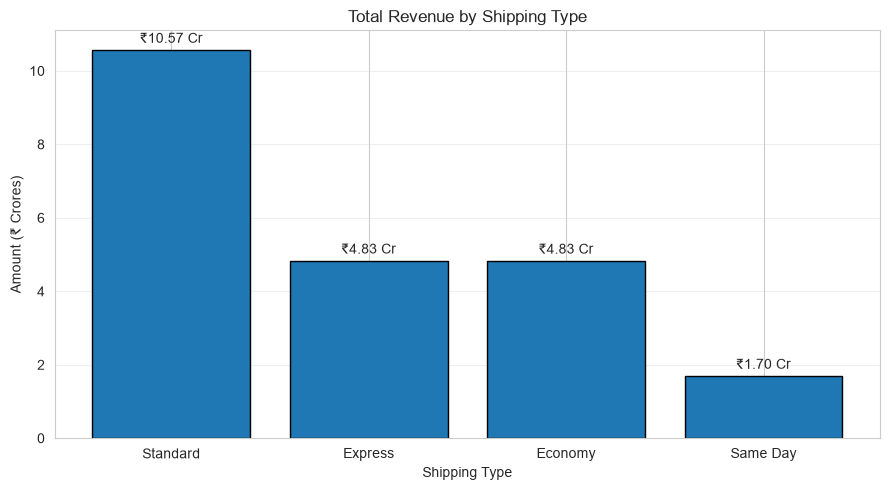

In [128]:
plot_crore_chart(
    shipping_financials,
    "Total_Revenue",
    "Total Revenue by Shipping Type",
    "Shipping Type"
)

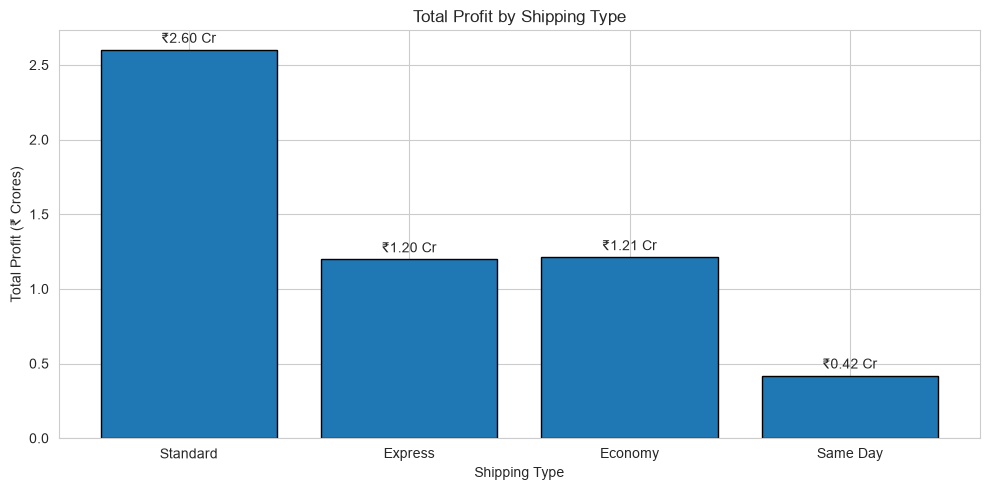

In [120]:
plt.figure(figsize=(10, 5))

profit_crores = shipping_financials["Total_Profit"] / 10000000

bars = plt.bar(
    shipping_financials.index,
    profit_crores,
    edgecolor="black"
)

plt.bar_label(
    bars,
    labels=[f"₹{value:.2f} Cr" for value in profit_crores],
    padding=3
)

plt.title("Total Profit by Shipping Type")
plt.xlabel("Shipping Type")
plt.ylabel("Total Profit (₹ Crores)")

plt.tight_layout()
plt.show()

In [121]:
# Calculate overall profit margin by shipping type
shipping_financials["Profit_Margin"] = (
    shipping_financials["Total_Profit"] /
    shipping_financials["Total_Revenue"]
) * 100

# Sort by profit margin
shipping_financials.sort_values(
    by="Profit_Margin",
    ascending=False
)

,Total_Revenue,Total_Profit,Total_Shipping_Cost,Total_Order_Lines,Profit_Margin,Avg_Shipping_Cost
Shipping_Type,,,,,,
Economy,4.829977e+07,12117764.59,8263631.32,26420,25.088659,314.565334
Express,4.831985e+07,11975235.59,10379628.44,26385,24.783264,395.715915
Same Day,1.695461e+07,4189771.28,4502118.89,9555,24.711687,473.707796
Standard,1.057074e+08,26009034.37,18143106.34,57640,24.604748,316.594942


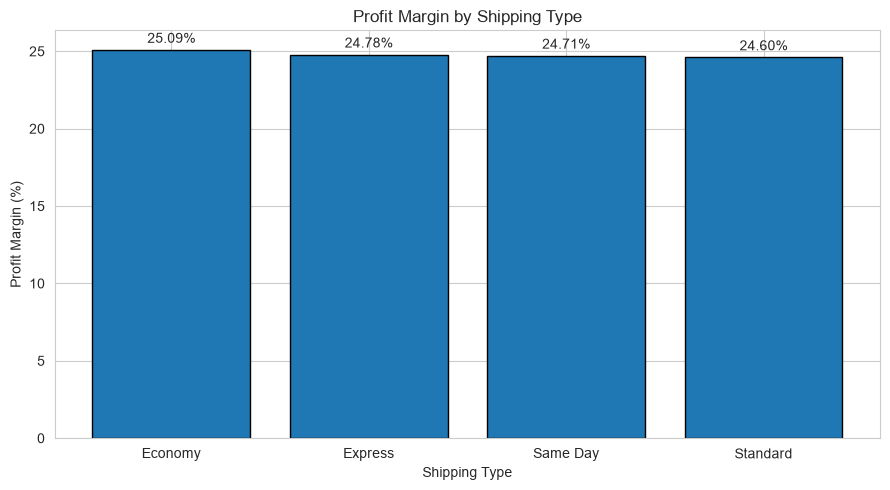

In [122]:
# Plot profit margin by shipping type
plt.figure(figsize=(9, 5))

shipping_sorted = shipping_financials.sort_values(
    by="Profit_Margin",
    ascending=False
)

bars = plt.bar(
    shipping_sorted.index,
    shipping_sorted["Profit_Margin"],
    edgecolor="black"
)

# Display percentage labels
plt.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in shipping_sorted["Profit_Margin"]
    ],
    padding=3
)

plt.title("Profit Margin by Shipping Type")
plt.xlabel("Shipping Type")
plt.ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

In [129]:
# Calculate return performance by product category
category_returns = df.groupby("Product_Category").agg(
    Total_Order_Lines=("Order_Line_ID", "count"),
    Returned_Order_Lines=("Return_Flag", lambda x: (x == "Yes").sum())
)

# Calculate return rate
category_returns["Return_Rate"] = (
    category_returns["Returned_Order_Lines"] /
    category_returns["Total_Order_Lines"]
) * 100

# Sort by return rate
category_returns = category_returns.sort_values(
    by="Return_Rate",
    ascending=False
)

category_returns

,Total_Order_Lines,Returned_Order_Lines,Return_Rate
Product_Category,,,
Home & Kitchen,19842,1198,6.037698
Automotive,19903,1192,5.989047
Apparel,20259,1206,5.952910
Grocery,19797,1168,5.899884
Office Supplies,20042,1149,5.732961
Electronics,20157,1128,5.596071


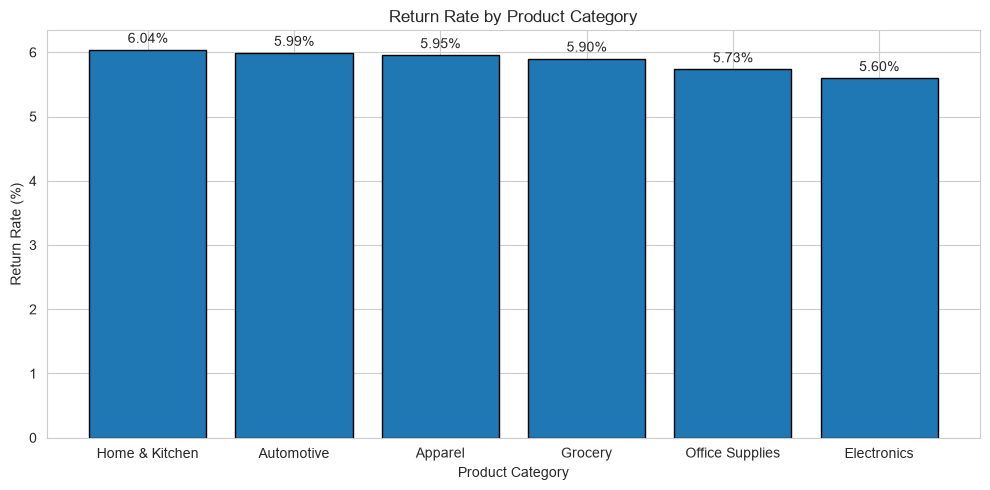

In [131]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    category_returns.index,
    category_returns["Return_Rate"],
    edgecolor="black"
)

plt.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in category_returns["Return_Rate"]
    ],
    padding=3
)

plt.title("Return Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Return Rate (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [132]:
# Calculate return performance by region
region_returns = df.groupby("Region").agg(
    Total_Order_Lines=("Order_Line_ID", "count"),
    Returned_Order_Lines=("Return_Flag", lambda x: (x == "Yes").sum())
)

# Calculate return rate
region_returns["Return_Rate"] = (
    region_returns["Returned_Order_Lines"] /
    region_returns["Total_Order_Lines"]
) * 100

# Sort by return rate
region_returns = region_returns.sort_values(
    by="Return_Rate",
    ascending=False
)

region_returns

,Total_Order_Lines,Returned_Order_Lines,Return_Rate
Region,,,
West,35853,2151,5.999498
East,12068,721,5.974478
South,47866,2776,5.799524
North,24213,1393,5.753108


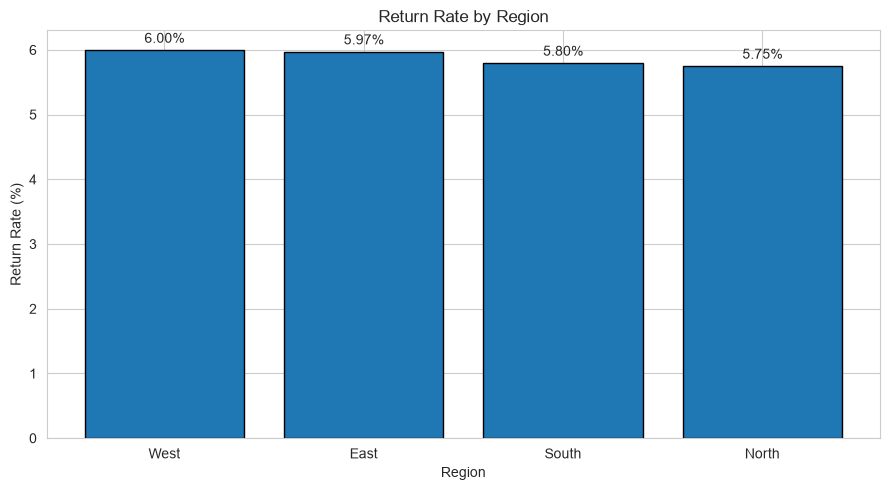

In [133]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    region_returns.index,
    region_returns["Return_Rate"],
    edgecolor="black"
)

plt.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in region_returns["Return_Rate"]
    ],
    padding=3
)

plt.title("Return Rate by Region")
plt.xlabel("Region")
plt.ylabel("Return Rate (%)")

plt.tight_layout()
plt.show()

In [134]:
# Calculate return performance by shipping type
shipping_returns = df.groupby("Shipping_Type").agg(
    Total_Order_Lines=("Order_Line_ID", "count"),
    Returned_Order_Lines=("Return_Flag", lambda x: (x == "Yes").sum())
)

# Calculate return rate
shipping_returns["Return_Rate"] = (
    shipping_returns["Returned_Order_Lines"] /
    shipping_returns["Total_Order_Lines"]
) * 100

# Sort by return rate
shipping_returns = shipping_returns.sort_values(
    by="Return_Rate",
    ascending=False
)

shipping_returns

,Total_Order_Lines,Returned_Order_Lines,Return_Rate
Shipping_Type,,,
Express,26385,1615,6.120902
Same Day,9555,583,6.101518
Standard,57640,3394,5.888272
Economy,26420,1449,5.484481


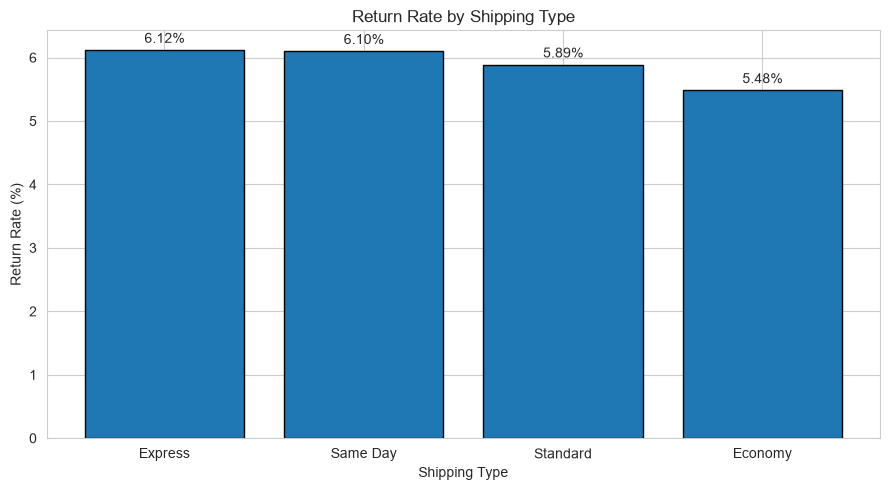

In [135]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    shipping_returns.index,
    shipping_returns["Return_Rate"],
    edgecolor="black"
)

plt.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in shipping_returns["Return_Rate"]
    ],
    padding=3
)

plt.title("Return Rate by Shipping Type")
plt.xlabel("Shipping Type")
plt.ylabel("Return Rate (%)")

plt.tight_layout()
plt.show()

In [136]:
# 1. Total rows and columns
print("Dataset Shape:", df.shape)

# 2. Duplicate records
print("Duplicate Order_Line_ID:",
      df["Order_Line_ID"].duplicated().sum())

# 3. Missing values in important columns
important_columns = [
    "Revenue",
    "Profit",
    "Profit_Margin",
    "Delivery_Days",
    "On_Time_Flag",
    "Return_Flag"
]

print("\nMissing Values:")
print(df[important_columns].isnull().sum())

# 4. Date range
print("\nOrder Date Range:")
print("Start Date:", df["Order_Date"].min())
print("End Date:", df["Order_Date"].max())

# 5. Financial validation
print("\nTotal Revenue:", df["Revenue"].sum())
print("Total Profit:", df["Profit"].sum())

Dataset Shape: (120000, 34)
Duplicate Order_Line_ID: 0

Missing Values:
Revenue           180
Profit            424
Profit_Margin     424
Delivery_Days    4262
On_Time_Flag     4204
Return_Flag         0
dtype: int64

Order Date Range:
Start Date: 2024-01-01 00:00:00
End Date: 2025-12-30 00:00:00

Total Revenue: 219281611.92000002
Total Profit: 54291805.83


In [137]:
overall_kpis = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Profit",
        "Overall Profit Margin",
        "Average Delivery Days",
        "On-Time Delivery Rate",
        "Overall Return Rate"
    ],
    "Value": [
        df["Revenue"].sum(),
        df["Profit"].sum(),
        (df["Profit"].sum() / df["Revenue"].sum()) * 100,
        df["Delivery_Days"].mean(),
        df["On_Time_Flag"].mean() * 100,
        (df["Return_Flag"] == "Yes").mean() * 100
    ]
})

overall_kpis

,KPI,Value
0,Total Revenue,2.192816e+08
1,Total Profit,5.429181e+07
2,Overall Profit Margin,2.475894e+01
3,Average Delivery Days,5.859536e+00
4,On-Time Delivery Rate,2.792843e+01
5,Overall Return Rate,5.867500e+00


In [138]:
overall_kpis["Value_Formatted"] = [
    f"₹{overall_kpis.loc[0, 'Value'] / 10000000:.2f} Cr",
    f"₹{overall_kpis.loc[1, 'Value'] / 10000000:.2f} Cr",
    f"{overall_kpis.loc[2, 'Value']:.2f}%",
    f"{overall_kpis.loc[3, 'Value']:.2f} days",
    f"{overall_kpis.loc[4, 'Value']:.2f}%",
    f"{overall_kpis.loc[5, 'Value']:.2f}%"
]

overall_kpis[["KPI", "Value_Formatted"]]

,KPI,Value_Formatted
0,Total Revenue,₹21.93 Cr
1,Total Profit,₹5.43 Cr
2,Overall Profit Margin,24.76%
3,Average Delivery Days,5.86 days
4,On-Time Delivery Rate,27.93%
5,Overall Return Rate,5.87%


In [6]:
# Export the final Python DataFrame
df.to_csv(
    "supply_chain_python_cleaned.csv",
    index=False
)

print("Dataset exported successfully!")

Dataset exported successfully!


In [7]:
import os

print(os.getcwd())

C:\Users\HP\Downloads\Complete Data Analysis Project\Python


In [8]:
import os

file_path = "supply_chain_python_cleaned.csv"

print("File Exists:", os.path.exists(file_path))
print("File Size:", os.path.getsize(file_path), "bytes")

File Exists: True
File Size: 28374662 bytes
